# Exploring the Dash *et al* dataset

This data was generated in [Quantifiable predictive features define epitope specific T cell  receptor repertoires](https://doi.org/10.1038/nature22383) and further analysed in [Measures of epitope binding degeneracy from T cell receptor repertoires](https://www.pnas.org/doi/abs/10.1073/pnas.2213264120). In this notebook we explore the dataset and re-create some of the analysis done in other works.

In [1]:
import subprocess

import anarci
import logomaker
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tidytcells
import umap
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from sklearn.cluster import HDBSCAN, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, v_measure_score
from sklearn.preprocessing import StandardScaler

from tcr_pmhc_predicted_structures.clustering import calculate_sequence_distances
from tcr_pmhc_predicted_structures.imgt_numbering import IMGT_CDR3

2026-06-09 17:58:46.918317: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 4

In [3]:
def plot_umap(
    umap: np.ndarray,
    clusters: np.ndarray,
    reference: np.ndarray | None = None,
    title: str | None = None,
    ax: Axes | None = None,
) -> Axes:
    clusters = clusters.copy()
    clusters[(clusters != 'None') & (clusters != 'Background')] = (
        'Cluster ' + clusters[(clusters != 'None') & (clusters != 'Background')]
    )

    ax = sns.scatterplot(
        x=umap[(clusters != 'None') & (clusters != 'Background'), 0],
        y=umap[(clusters != 'None') & (clusters != 'Background'), 1],
        hue=clusters[(clusters != 'None') & (clusters != 'Background')],
        style=reference[(clusters != 'None') & (clusters != 'Background')] if reference is not None else None,
        alpha=0.65,
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'None', 0],
        y=umap[clusters == 'None', 1],
        color='grey',
        alpha=0.55,
        label='None',
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'Background', 0],
        y=umap[clusters == 'Background', 1],
        marker='x',
        color='black',
        alpha=0.55,
        label='Background',
        ax=ax,
    )

    ax.set_title(title)
    ax.legend(title='Cluster')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    return ax


def plot_umap_with_experimental_structure(
    umap: np.ndarray,
    clusters: np.ndarray,
    experimental_structure: np.ndarray,
    reference: np.ndarray | None = None,
    title: str | None = None,
    ax: Axes | None = None,
) -> Axes:
    clusters = clusters.copy()
    clusters[~experimental_structure & (clusters != 'None') & (clusters != 'Background')] = (
        'Cluster ' + clusters[~experimental_structure & (clusters != 'None') & (clusters != 'Background')]
    )

    ax = sns.scatterplot(
        x=umap[~experimental_structure & (clusters != 'None') & (clusters != 'Background'), 0],
        y=umap[~experimental_structure & (clusters != 'None') & (clusters != 'Background'), 1],
        hue=clusters[~experimental_structure & (clusters != 'None') & (clusters != 'Background')],
        style=(
            reference[~experimental_structure & (clusters != 'None') & (clusters != 'Background')]
            if reference is not None
            else None
        ),
        alpha=0.65,
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'None', 0],
        y=umap[clusters == 'None', 1],
        color='grey',
        alpha=0.55,
        label='None',
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'Background', 0],
        y=umap[clusters == 'Background', 1],
        marker='x',
        color='black',
        alpha=0.55,
        label='Background',
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[experimental_structure, 0],
        y=umap[experimental_structure, 1],
        marker='^',
        color='red',
        label='Experimental Structure',
        ax=ax,
    )

    ax.set_title(title)
    ax.legend(title='Cluster')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    return ax


def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def make_logo_plot(cluster: pd.DataFrame, *, save: bool = False, save_name: str | None = None) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(10, 5), gridspec_kw={'width_ratios': (1, 5, 1), 'wspace': 0.1}, sharey=True)
    fig.suptitle(f'Cluster {cluster.name}')

    for chain_type, axes_row in zip(('a', 'b'), axes, strict=True):
        axes_row[0].set_ylabel({'a': 'Alpha Chain', 'b': 'Beta Chain'}[chain_type], fontsize=14)

        aligned_sequences = align_sequences(cluster[f'cdr3_{chain_type}_aa'])
        probs = logomaker.alignment_to_matrix(aligned_sequences, to_type='counts')

        logomaker.Logo(probs, color_scheme='chemistry', show_spines=False, baseline_width=0.0, ax=axes_row[1])

        axes_row[1].set_xticks([])
        axes_row[1].set_yticks([])

        counts_v = cluster[f'v_{chain_type}_gene'].value_counts()
        counts_j = cluster[f'j_{chain_type}_gene'].value_counts()

        for ax, counts in zip([axes_row[0], axes_row[2]], [counts_v, counts_j], strict=True):
            previous_count = 0
            for gene_name, cum_count in counts.cumsum().items():
                logomaker.Glyph(0.5, gene_name[3:], previous_count, cum_count, ax=ax)
                previous_count = cum_count

            ax.set_xticks([])
            ax.set_yticks([])
            ax.spines[:].set_visible(False)

    if save:
        plt.savefig(save_name.format(cluster_name=cluster.name))


def plot_sequence_distances(
    distance_matrix: np.ndarray,
    cluster_colours: np.ndarray,
    cluster_order: np.ndarray,
    cluster_counts: np.ndarray,
    new_order: np.ndarray,
    subject_colours: np.ndarray,
    epitope_colours: np.ndarray | None = None,
) -> tuple[Figure, np.ndarray[Axes]]:
    if epitope_colours is not None:
        fig, axes = plt.subplots(1, 4, gridspec_kw={'width_ratios': [1, 1, 1, 20]})

    else:
        fig, axes = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

    idx = 0

    axes[idx].imshow(subject_colours, aspect='auto')

    axes[idx].set_ylabel('Subject', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    idx += 1

    if epitope_colours is not None:
        axes[idx].imshow(epitope_colours, aspect='auto')

        axes[idx].set_ylabel('Epitope', fontsize=14)
        axes[idx].set_xticks([])
        axes[idx].set_xticklabels('')
        axes[idx].set_yticks([])
        axes[idx].set_yticklabels('')

        idx += 1

    axes[idx].imshow(cluster_colours, aspect='auto')

    axes[idx].set_ylabel('Cluster', fontsize=14)
    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    accumulation = 0
    for cluster in cluster_order:
        cluster_size = cluster_counts[cluster]

        if cluster_size >= MIN_CLUSTER_SIZE:
            position = cluster_counts[cluster] // 2 + accumulation
            axes[idx].text(
                x=0.025,
                y=position,
                s=str(cluster),
                va='center',
                ha='center',
                fontsize=8,
            )

        accumulation += cluster_size

    idx += 1

    sns.heatmap(
        np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE),
        cmap='viridis_r',
        ax=axes[idx],
    )

    axes[idx].set_xlabel(r'CDR3$\alpha$', fontsize=14)
    axes[idx].set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
    axes[idx].yaxis.set_label_position('right')

    axes[idx].set_xticks([])
    axes[idx].set_xticklabels('')
    axes[idx].set_yticks([])
    axes[idx].set_yticklabels('')

    cbar = axes[idx].collections[0].colorbar
    cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
    cbar.set_ticks(cbar.get_ticks())
    cbar.set_ticklabels(
        [f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()]
    )

    fig.set_layout_engine('tight')

    return fig, axes

In [4]:
dash = pd.read_csv('../data/external/dash_human.csv')
dash.index.name = 'id'
dash = dash.reset_index()
dash['id'] = 'dash_' + dash['id'].astype(str)

In [5]:
dash = dash.dropna()

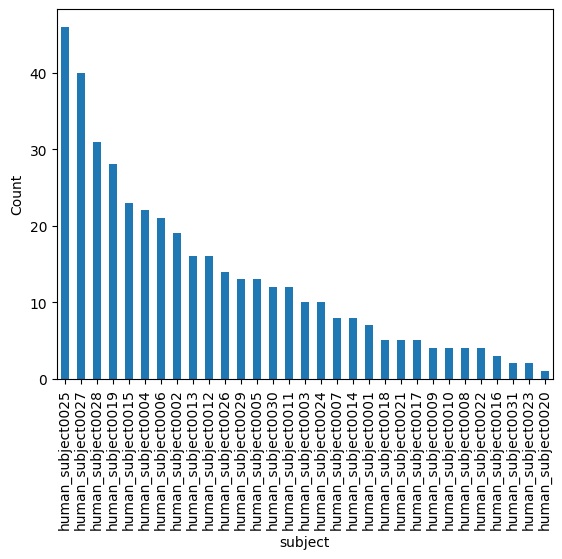

In [6]:
dash['subject'].value_counts().plot.bar()

plt.ylabel('Count')

plt.show()

In [7]:
dash.value_counts('epitope')

epitope
M1      249
BMLF     92
pp65     67
Name: count, dtype: int64

In [8]:
epitope_info = pd.DataFrame(
    columns=['name', 'species', 'mhc', 'peptide_seq', 'virus'],
    data=[
        ['BMLF', 'human', 'HLA-A*02:01', 'GLCTLVAML', 'EBV'],
        ['M1', 'human', 'HLA-A*02:01', 'GILGFVFTL', 'IAV'],
        ['pp65', 'human', 'HLA-A*02:01', 'NLVPMVATV', 'CMV'],
    ],
)

epitope_info.set_index('name')

,species,mhc,peptide_seq,virus
name,,,,
BMLF,human,HLA-A*02:01,GLCTLVAML,EBV
M1,human,HLA-A*02:01,GILGFVFTL,IAV
pp65,human,HLA-A*02:01,NLVPMVATV,CMV


In [9]:
sequences_with_negatives = pd.read_csv('../data/interim/sequences_dash_with_negatives.csv')

sequences_with_negatives = sequences_with_negatives.merge(dash, how='left', on='id')

sequences_with_negatives.loc[sequences_with_negatives['subject'].isna(), 'subject'] = 'Background'
sequences_with_negatives.loc[sequences_with_negatives['epitope'].isna(), 'epitope'] = 'Background'

In [10]:
def get_cdr3(sequence: str) -> str:
    numbering, _ = anarci.number(sequence)
    cdr3 = ''.join(amino_acid for (seq_id, _), amino_acid in numbering if amino_acid != '-' and seq_id in IMGT_CDR3)
    return tidytcells.junction.standardise(cdr3)


sequences_with_negatives['cdr3_alpha'] = sequences_with_negatives['tcr_alpha_chain'].apply(get_cdr3)
sequences_with_negatives['cdr3_beta'] = sequences_with_negatives['tcr_beta_chain'].apply(get_cdr3)

In [11]:
sequences_with_negatives = sequences_with_negatives.merge(
    epitope_info[['name', 'mhc', 'peptide_seq', 'virus']], how='left', left_on='peptide', right_on='peptide_seq'
)

In [12]:
distance_matrix = calculate_sequence_distances(
    sequences_with_negatives['cdr3_alpha'].tolist(), sequences_with_negatives['cdr3_beta'].tolist()
)
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [13]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [14]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [15]:
clusters_filtered = np.array(
    [str(cluster) if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else 'None' for cluster in clusters]
)

In [16]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [17]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [18]:
unique_subjects = sorted(sequences_with_negatives['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array(
    [[subject_to_colour[subject]] for subject in sequences_with_negatives['subject'].to_numpy()[new_order]]
)

In [19]:
unique_epitopes = sorted(sequences_with_negatives['epitope'].unique())
epitope_to_colour = {epitope: palette[i % num_colours] for i, epitope in enumerate(unique_epitopes)}
epitope_colours = np.array(
    [[epitope_to_colour[epitope]] for epitope in sequences_with_negatives['epitope'].to_numpy()[new_order]]
)

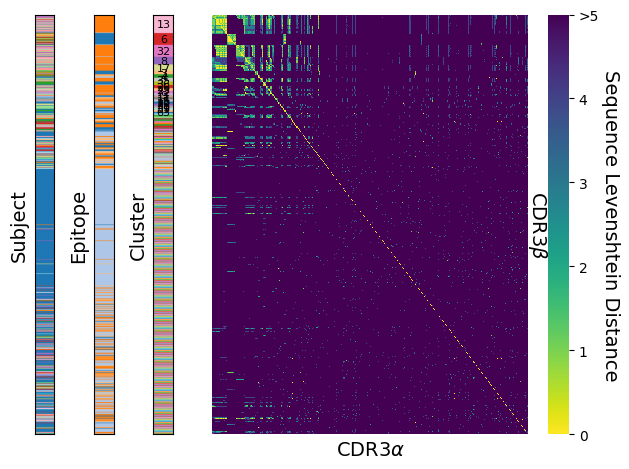

In [20]:
plot_sequence_distances(
    distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours, epitope_colours
)

plt.savefig('../report/figures/dash_all_epitopes_sequence_distances.png')
plt.show()

In [21]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

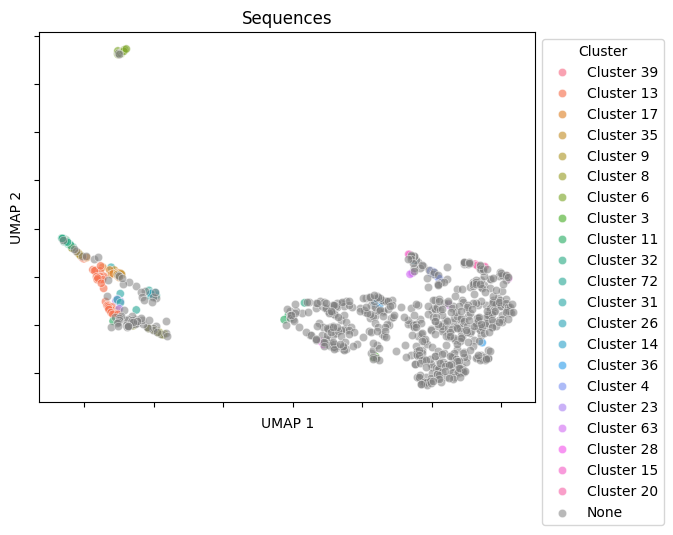

In [22]:
ax = plot_umap(sequence_umap, pd.Series(clusters_filtered), title='Sequences')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))

plt.savefig('../report/figures/dash_all_epitopes_sequence_umap.svg')
plt.show()

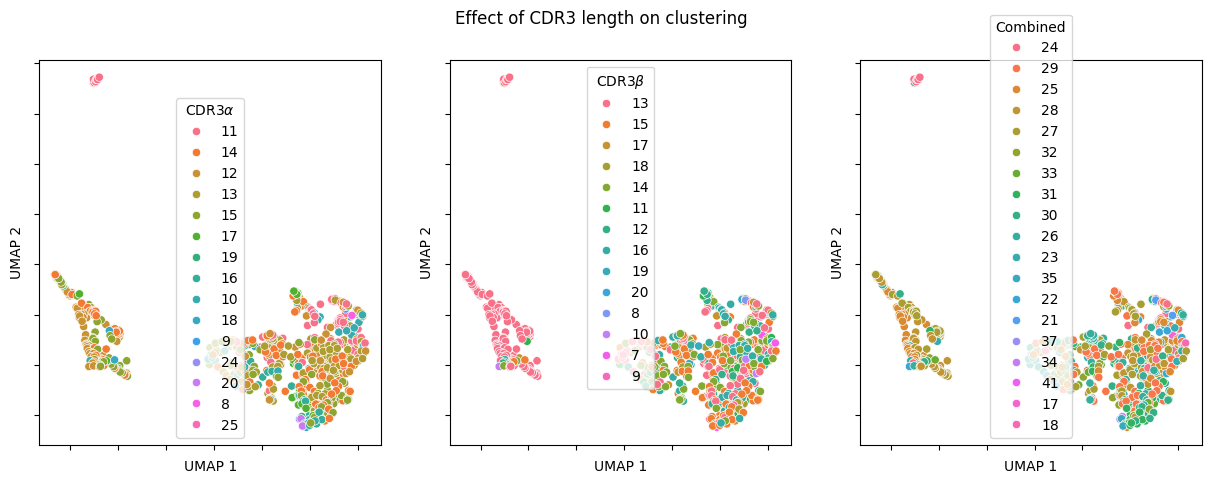

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.suptitle('Effect of CDR3 length on clustering')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=sequences_with_negatives['cdr3_alpha'].str.len().astype(str),
    ax=axes[0],
)
axes[0].legend(title=r'CDR3$\alpha$')

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])

axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=sequences_with_negatives['cdr3_beta'].str.len().astype(str),
    ax=axes[1],
)
axes[1].legend(title=r'CDR3$\beta$')

axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=(sequences_with_negatives['cdr3_alpha'].str.len() + sequences_with_negatives['cdr3_beta'].str.len()).astype(
        str
    ),
    ax=axes[2],
)
axes[2].legend(title=r'Combined')

axes[2].set_yticklabels([])
axes[2].set_xticklabels([])

axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')

plt.show()

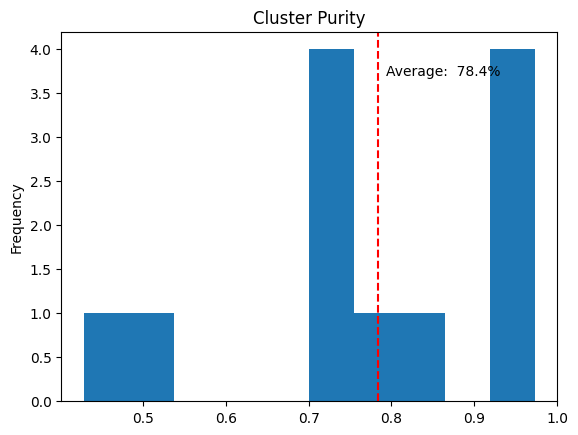

In [24]:
cluster_purities = (
    sequences_with_negatives.groupby(clusters_filtered)['epitope']
    .value_counts(normalize=True)
    .reset_index()
    .groupby('level_0')
    .filter(lambda group: group['epitope'].nunique() > 1 and 'Background' not in group['epitope'])  # noqa: PD101
    .groupby('level_0')
    .agg({'proportion': 'max'})
    .reset_index()
    .query("level_0 != 'None'")
)

cluster_purities['proportion'].plot.hist()

purity_mean = cluster_purities['proportion'].mean()
plt.axvline(purity_mean, color='red', linestyle='dashed')
plt.text(purity_mean + 0.01, plt.ylim()[1] - 0.5, f'Average: {purity_mean * 100: .1f}%')

plt.title('Cluster Purity')

plt.show()

## M1 Epitope Analysis

In [25]:
dash_m1 = dash.query("epitope == 'M1'").copy()

In [26]:
distance_matrix = calculate_sequence_distances(dash_m1['cdr3_a_aa'].tolist(), dash_m1['cdr3_b_aa'].tolist())
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [27]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [28]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [29]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [30]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [31]:
unique_subjects = sorted(dash_m1['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_m1['subject'].to_numpy()[new_order]])

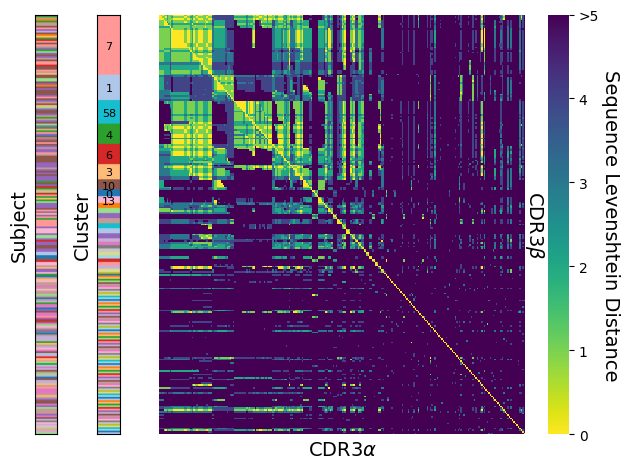

In [32]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)

plt.savefig('../report/figures/dash_m1_sequence_distances.svg')
plt.show()

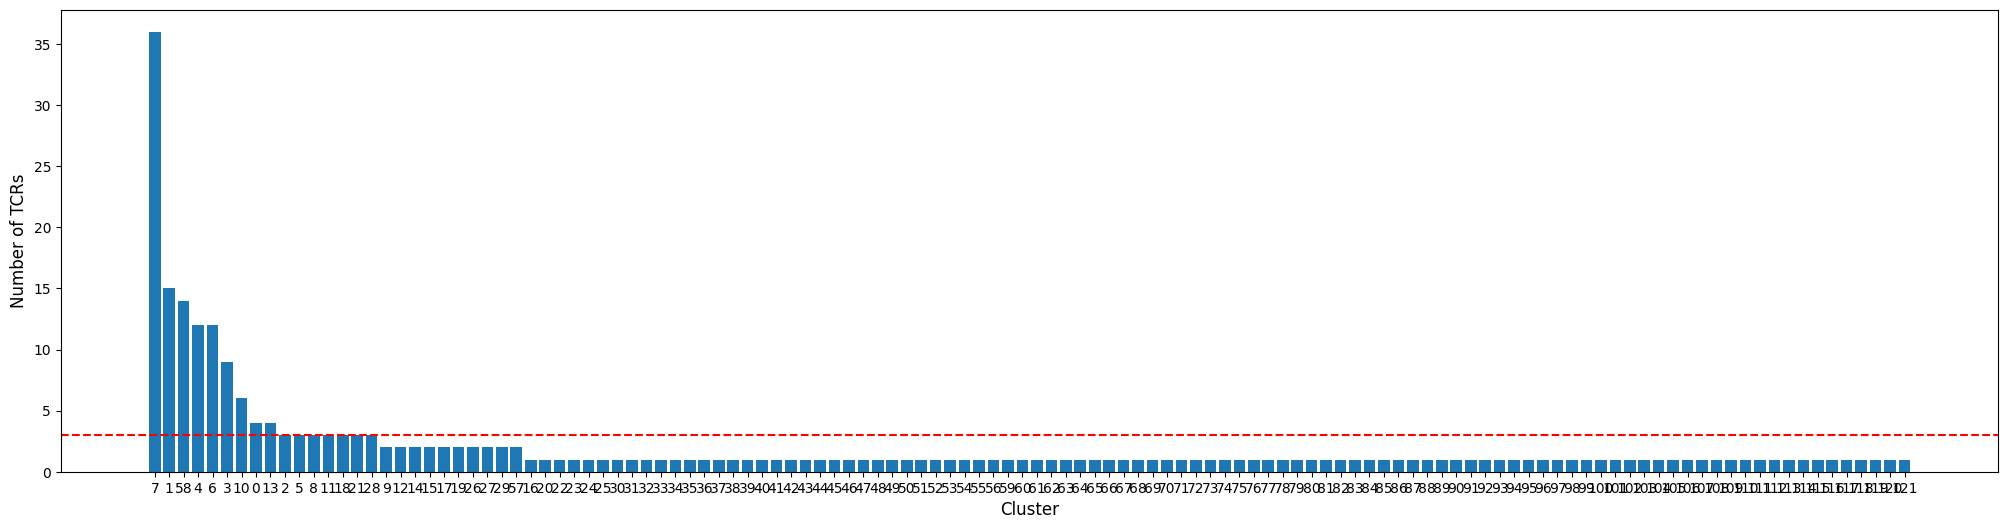

In [33]:
plt.figure(figsize=(25, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [34]:
clusters_filtered = np.array([cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters])

In [35]:
dash_m1['cluster'] = clusters_filtered
dash_m1['cluster'] = dash_m1['cluster'].astype(str)
dash_m1['cluster'] = dash_m1['cluster'].replace('-1', 'None')

""


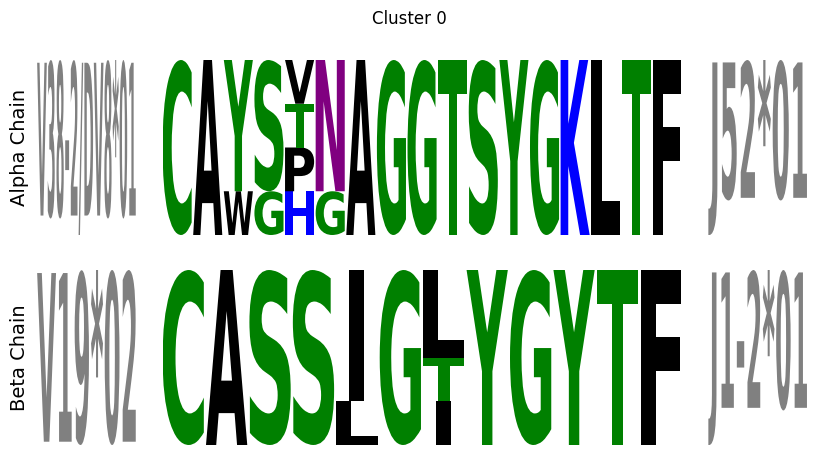

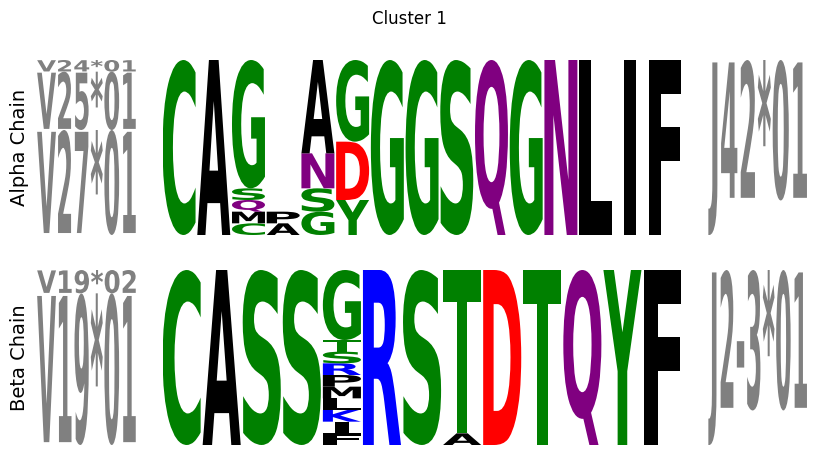

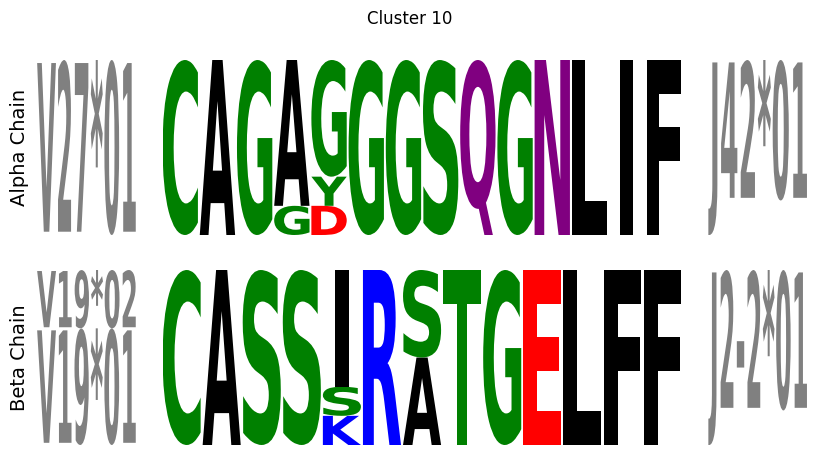

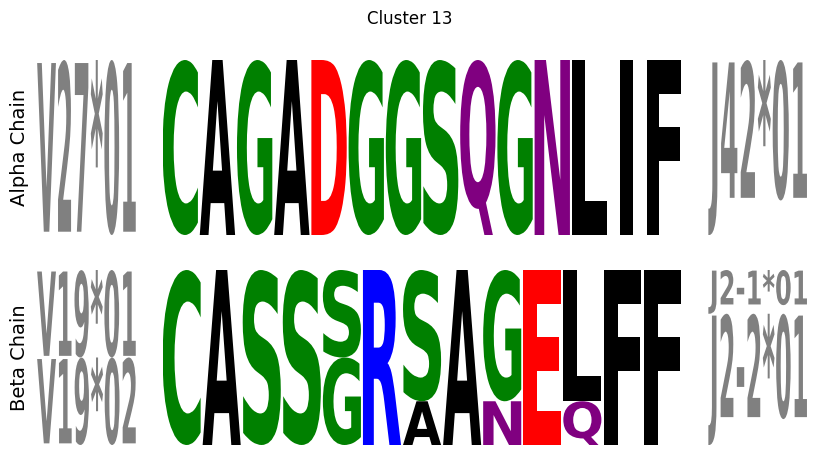

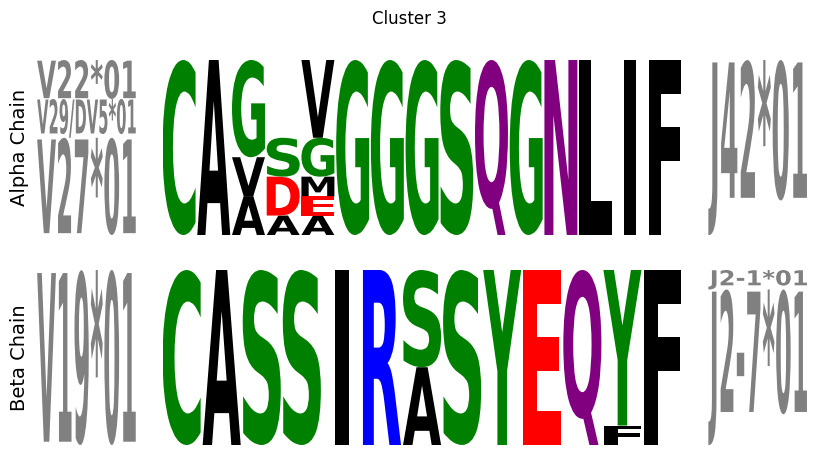

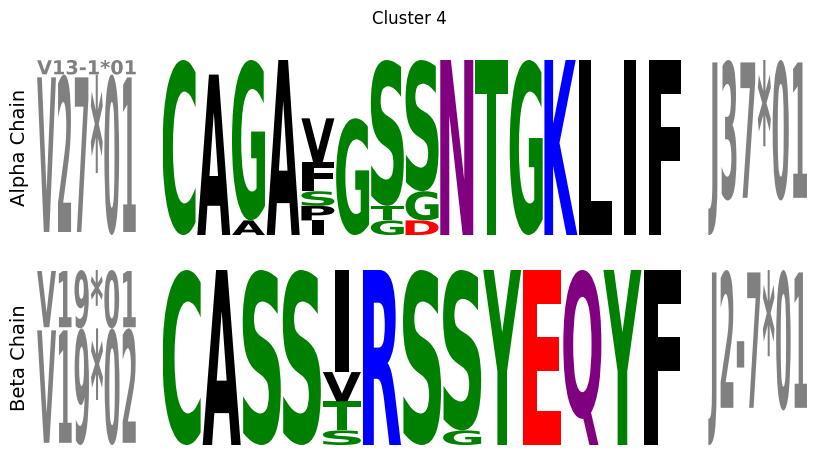

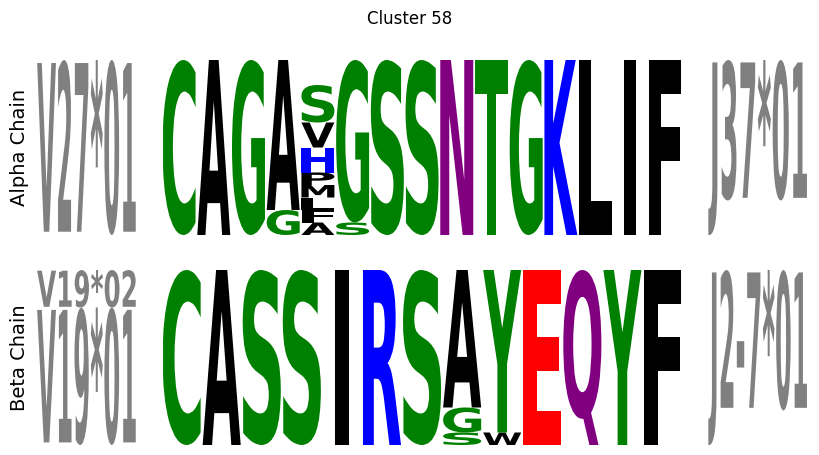

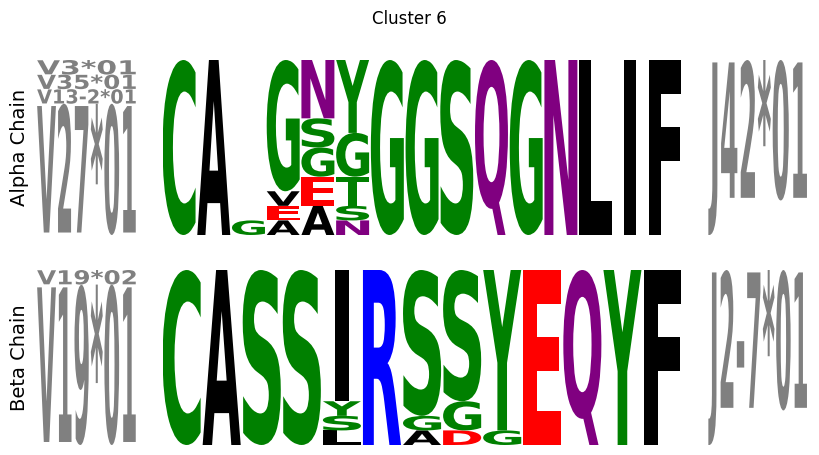

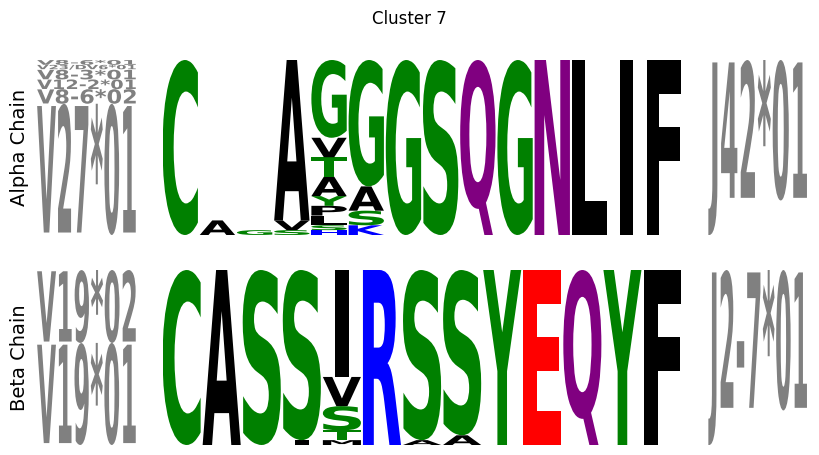

In [36]:
dash_m1.query("cluster != 'None'").groupby('cluster').apply(
    make_logo_plot,
    save=True,
    save_name='../report/figures/dash_m1_motif_cluster_{cluster_name}.svg',
    include_groups=False,
)

In [37]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

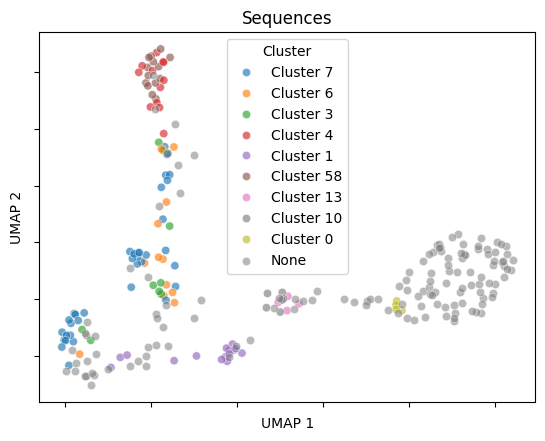

In [38]:
plot_umap(sequence_umap, dash_m1['cluster'], title='Sequences')

plt.savefig('../report/figures/dash_m1_sequence_umap.svg')
plt.show()

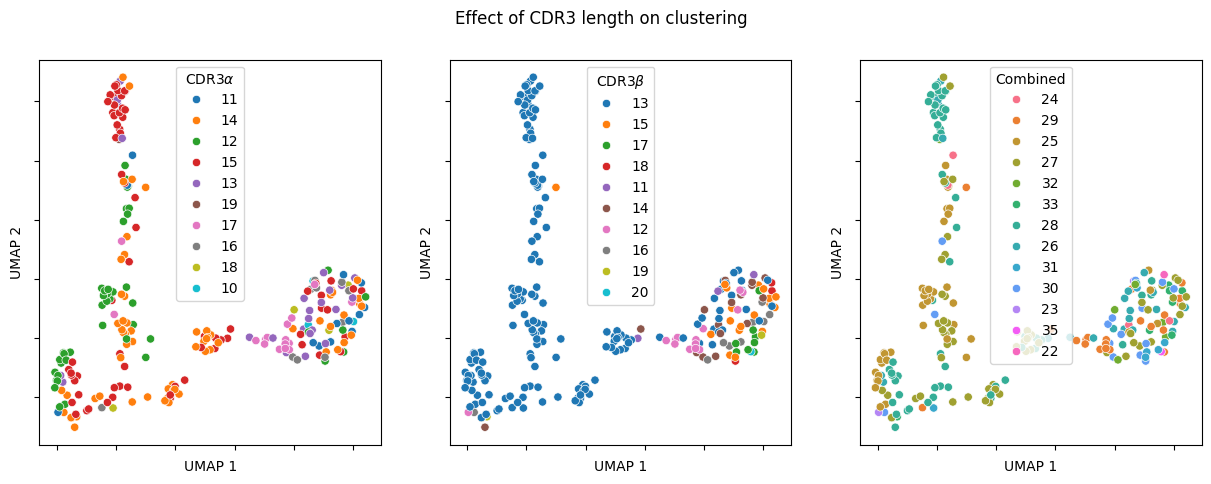

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.suptitle('Effect of CDR3 length on clustering')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_m1['cdr3_a_aa'].str.len().astype(str), ax=axes[0]
)
axes[0].legend(title=r'CDR3$\alpha$')

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])

axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_m1['cdr3_b_aa'].str.len().astype(str), ax=axes[1]
)
axes[1].legend(title=r'CDR3$\beta$')

axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=(dash_m1['cdr3_a_aa'].str.len() + dash_m1['cdr3_b_aa'].str.len()).astype(str),
    ax=axes[2],
)
axes[2].legend(title=r'Combined')

axes[2].set_yticklabels([])
axes[2].set_xticklabels([])

axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')

plt.show()

In [40]:
sequences_with_negatives_m1 = sequences_with_negatives.query("name == 'M1'")

In [41]:
sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1 = sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1['cluster'] = sequences_with_negatives_m1['cluster'].fillna('Background')

In [42]:
distance_matrix = calculate_sequence_distances(
    sequences_with_negatives_m1['cdr3_alpha'].tolist(), sequences_with_negatives_m1['cdr3_beta'].tolist()
)
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [43]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

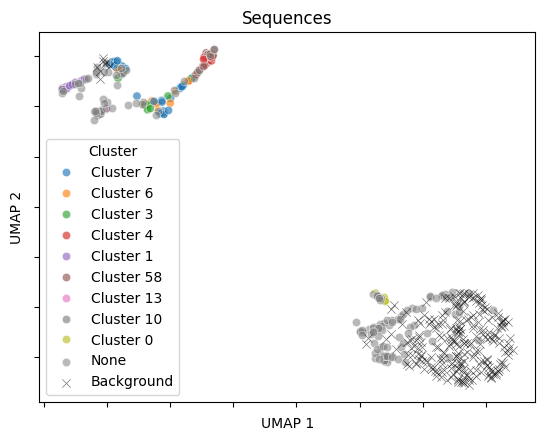

In [44]:
plot_umap(sequence_umap_with_background, sequences_with_negatives_m1['cluster'], title='Sequences')

plt.savefig('../report/figures/dash_m1_sequence_umap_with_negatives.svg')
plt.show()

## BMLF Epitope Analysis

In [45]:
dash_bmlf = dash.query("epitope == 'BMLF'").copy()

In [46]:
distance_matrix = calculate_sequence_distances(dash_bmlf['cdr3_a_aa'].tolist(), dash_bmlf['cdr3_b_aa'].tolist())
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [47]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [48]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [49]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [50]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [51]:
unique_subjects = sorted(dash_bmlf['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_bmlf['subject'].to_numpy()[new_order]])

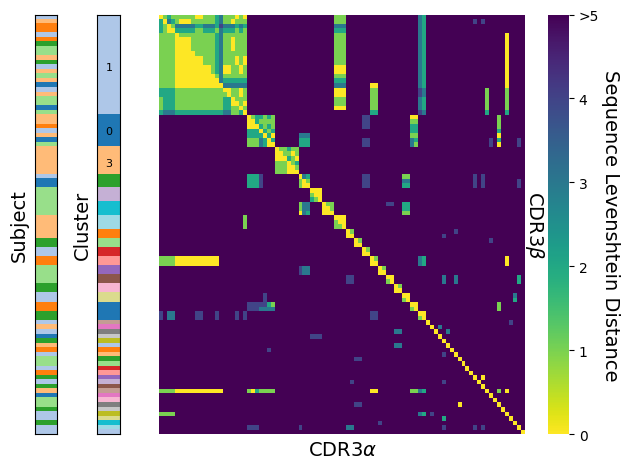

In [52]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)

plt.savefig('../report/figures/dash_bmlf_sequence_distances.svg')
plt.show()

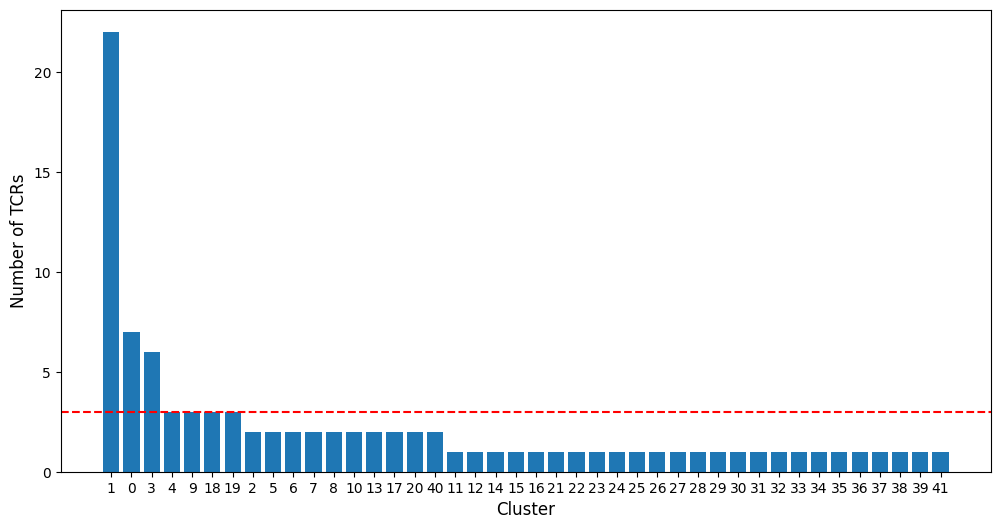

In [53]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [54]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [55]:
dash_bmlf['cluster'] = clusters_filtered
dash_bmlf['cluster'] = dash_bmlf['cluster'].astype(str)
dash_bmlf['cluster'] = dash_bmlf['cluster'].replace('-1', 'None')

""


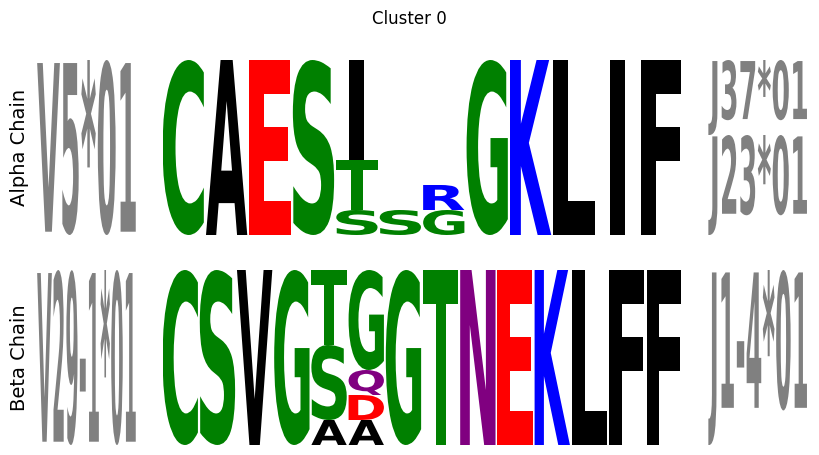

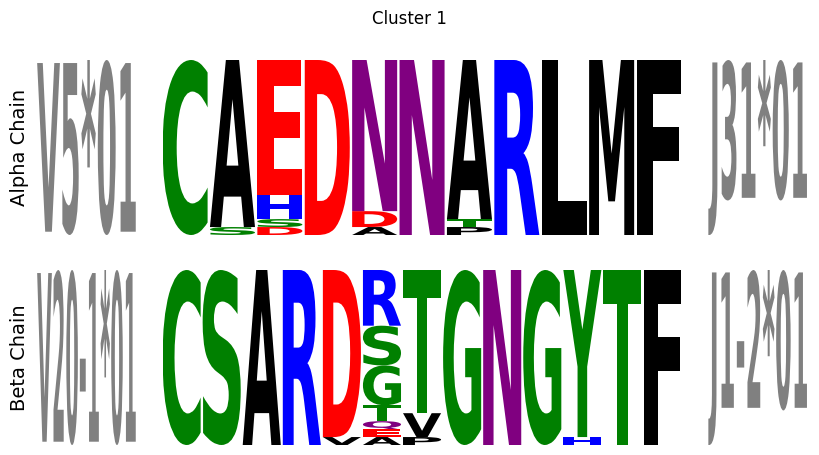

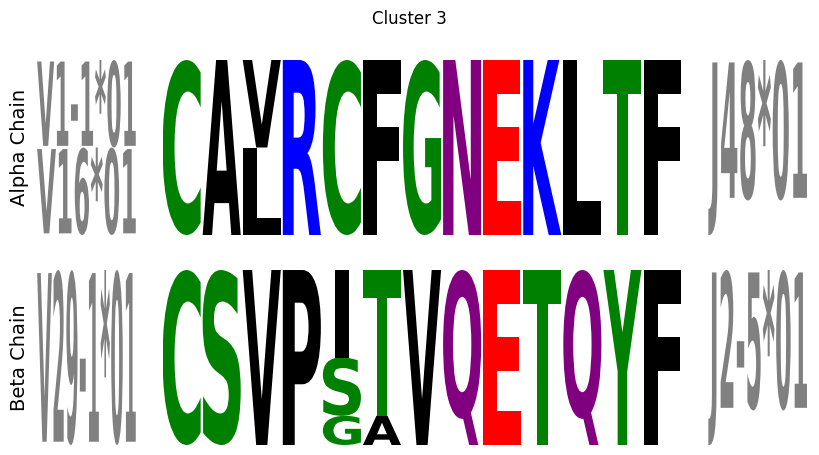

In [56]:
dash_bmlf.query("cluster != 'None'").groupby('cluster').apply(
    make_logo_plot,
    save=True,
    save_name='../report/figures/dash_bmlf_motif_cluster_{cluster_name}.svg',
    include_groups=False,
)

In [57]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

In [58]:
structure_summary = pd.read_csv('../data/interim/structures_summary.csv')
structure_summary['name'] = structure_summary['path'].str.replace('.pdb', '')
structure_summary = structure_summary.set_index('name')

bmlf_structures = structure_summary.query("peptide == 'GLCTLVAML'")
bmlf_structures

,path,pdb,Achain,Bchain,antigen_chain,mhc_chain1,mhc_chain2,mhc_type,cdr1_alpha,cdr2_alpha,...,cdr1_beta,cdr2_beta,cdr3_beta,v_alpha,v_beta,peptide,mhc1,mhc2,species,mhc_pseudo
name,,,,,,,,,,,,,,,,,,,,,
3o4l_DECAB,3o4l_DECAB.pdb,3o4l,D,E,C,A,NaN,MH1,DSSSTY,IFSNMDM,...,DFQATT,SNEGSKA,SARDGTGNGYT,TRAV5,TRBV20,GLCTLVAML,HLA-A*02:01,B2M,Human,GERKKAHQTRVGKAHVEQLAYEGTEW


In [59]:
dash_bmlf['has_structure'] = dash_bmlf.apply(
    lambda row: (
        (row.cdr3_a_aa[1:-1] == bmlf_structures.iloc[0]['cdr3_alpha'])
        and (row.cdr3_b_aa[1:-1] == bmlf_structures.iloc[0]['cdr3_beta'])
    ),
    axis=1,
)

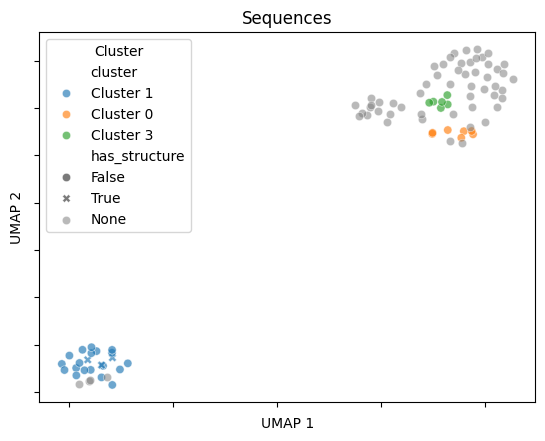

In [60]:
plot_umap(sequence_umap, dash_bmlf['cluster'], reference=dash_bmlf['has_structure'], title='Sequences')

plt.savefig('../report/figures/dash_bmlf_sequence_umap.svg')
plt.show()

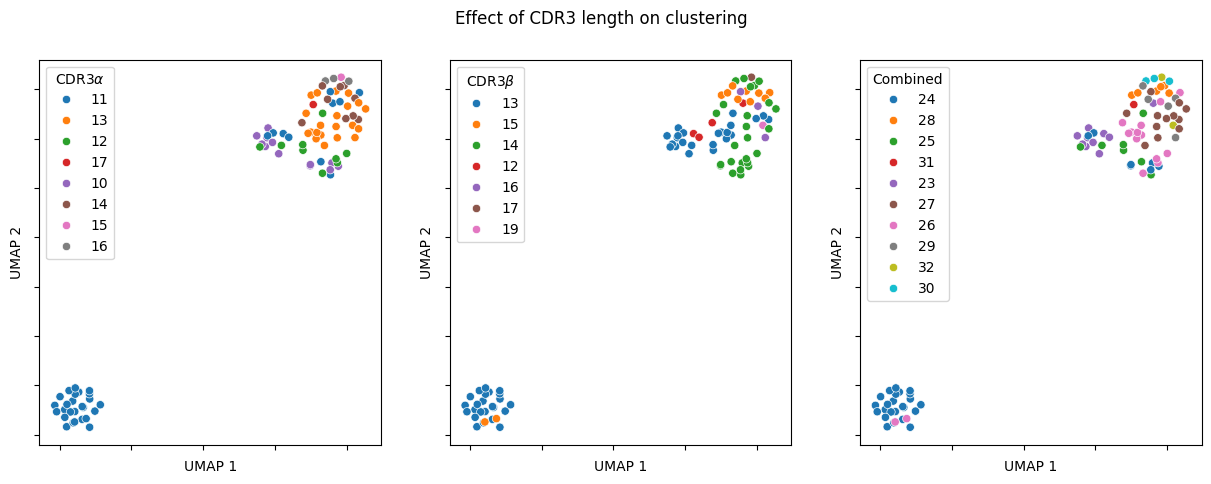

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.suptitle('Effect of CDR3 length on clustering')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_bmlf['cdr3_a_aa'].str.len().astype(str), ax=axes[0]
)
axes[0].legend(title=r'CDR3$\alpha$')

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])

axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_bmlf['cdr3_b_aa'].str.len().astype(str), ax=axes[1]
)
axes[1].legend(title=r'CDR3$\beta$')

axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=(dash_bmlf['cdr3_a_aa'].str.len() + dash_bmlf['cdr3_b_aa'].str.len()).astype(str),
    ax=axes[2],
)
axes[2].legend(title=r'Combined')

axes[2].set_yticklabels([])
axes[2].set_xticklabels([])

axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')

plt.show()

In [62]:
sequences_with_negatives_bmlf = sequences_with_negatives.query("name == 'BMLF'")

In [63]:
sequences_with_negatives_bmlf = sequences_with_negatives_bmlf.merge(
    dash_bmlf[['id', 'cluster', 'has_structure']], how='left', on='id'
)
sequences_with_negatives_bmlf['cluster'] = sequences_with_negatives_bmlf['cluster'].fillna('Background')

In [64]:
distance_matrix = calculate_sequence_distances(
    sequences_with_negatives_bmlf['cdr3_alpha'].tolist(), sequences_with_negatives_bmlf['cdr3_beta'].tolist()
)
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [65]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

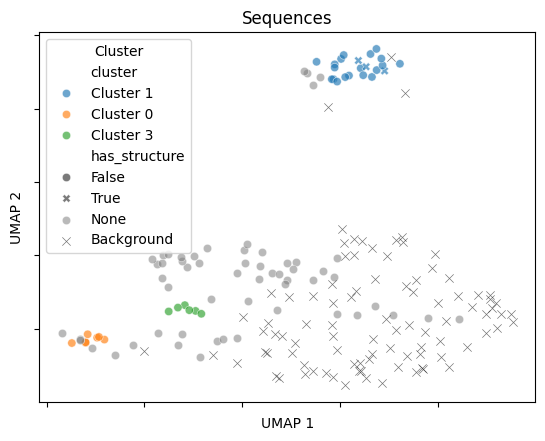

In [66]:
plot_umap(
    sequence_umap_with_background,
    sequences_with_negatives_bmlf['cluster'],
    reference=sequences_with_negatives_bmlf['has_structure'],
    title='Sequences',
)

plt.savefig('../report/figures/dash_bmlf_sequence_umap_with_negatives.svg')
plt.show()

### Structure Prediction Features

In [67]:
def is_constant(column: pd.Series) -> bool:
    return (column == column.iloc[0]).all()


def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    return df[[column_name for column_name in df.columns if not is_constant(df[column_name])]]

#### Confidence Scores

In [68]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_dash_bmlf.csv')
confidence_scores['top_rank'] = False
confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [69]:
confidence_scores = confidence_scores.merge(dash_bmlf, how='left', left_on='name', right_on='id')
confidence_scores['cluster'] = confidence_scores['cluster'].fillna('Background')

In [70]:
confidence_scores = confidence_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)
confidence_scores_without_negatives = confidence_scores.query("cluster != 'Background'")

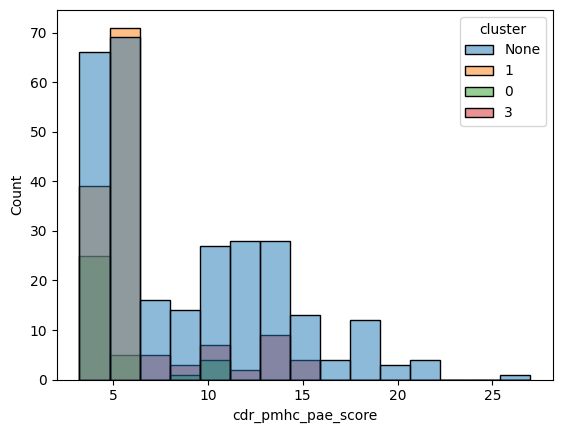

In [71]:
sns.histplot(confidence_scores_without_negatives, x='cdr_pmhc_pae_score', hue='cluster')

plt.show()

In [72]:
confidence_scores_values_without_negatives = confidence_scores_without_negatives.select_dtypes('number')
confidence_scores_values_without_negatives = confidence_scores_values_without_negatives[
    [
        column_name
        for column_name in confidence_scores_values_without_negatives.columns
        if column_name not in ('count', 'sample', 'seed')
    ]
]

confidence_scores_values_without_negatives = drop_constant_columns(confidence_scores_values_without_negatives)
confidence_scores_values_without_negatives = confidence_scores_values_without_negatives.to_numpy()

In [73]:
confidence_scores_values_norm_without_negatives = StandardScaler().fit_transform(
    confidence_scores_values_without_negatives
)
confidence_scores_umap_without_negatives = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    confidence_scores_values_norm_without_negatives
)

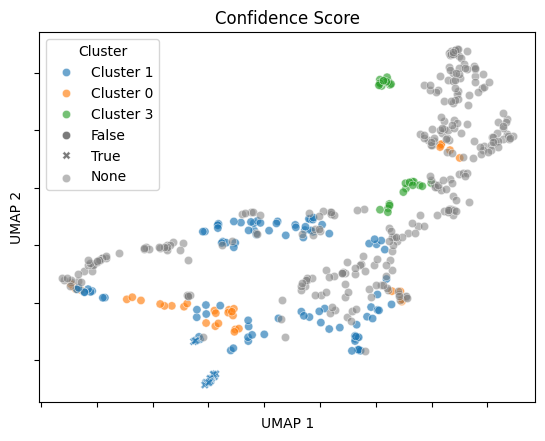

In [74]:
plot_umap(
    confidence_scores_umap_without_negatives,
    confidence_scores_without_negatives['cluster'].to_numpy(),
    reference=confidence_scores_without_negatives['has_structure'].to_numpy(),
    title='Confidence Score',
)
plt.show()

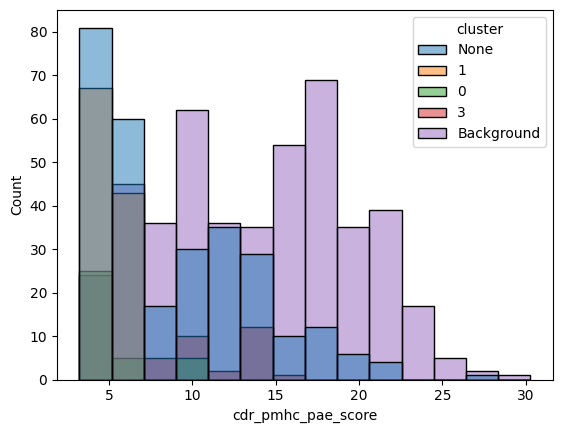

In [75]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score', hue='cluster')

plt.show()

In [76]:
confidence_scores_values = confidence_scores.select_dtypes('number')
confidence_scores_values = confidence_scores_values[
    [column_name for column_name in confidence_scores_values.columns if column_name not in ('count', 'sample', 'seed')]
]

confidence_scores_values = drop_constant_columns(confidence_scores_values)
confidence_scores_values = confidence_scores_values.to_numpy()

In [77]:
confidence_scores_values_norm = StandardScaler().fit_transform(confidence_scores_values)
confidence_scores_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(confidence_scores_values_norm)

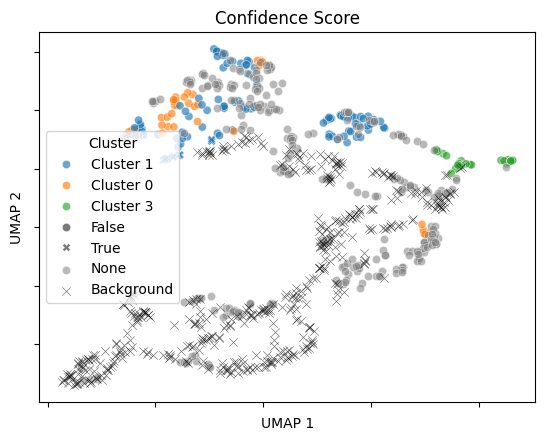

In [78]:
plot_umap(
    confidence_scores_umap,
    confidence_scores['cluster'].to_numpy(),
    reference=confidence_scores['has_structure'].to_numpy(),
    title='Confidence Score',
)
plt.show()

#### Structural Features

In [79]:
bmlf_structure_features = pd.read_csv('../data/processed/tcr_pmhc_structural_features.csv').merge(
    bmlf_structures, how='inner', left_on='name', right_index=True
)
bmlf_structure_features['experimental_structure'] = True

In [80]:
structure_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_dash_bmlf.csv')
structure_features['experimental_structure'] = False

In [81]:
structure_features = pd.concat([structure_features, bmlf_structure_features]).reset_index(drop=True)

In [82]:
structure_features = structure_features.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
structure_features['cluster'] = structure_features['cluster'].fillna('Background')

structure_features.loc[structure_features['experimental_structure'], 'cluster'] = None

In [83]:
structure_features = structure_features.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)
structure_features_without_background = structure_features.query("cluster != 'Background'")

In [84]:
structure_features_without_background_values = structure_features_without_background.select_dtypes('number')
structure_features_without_background_values = structure_features_without_background_values[
    [
        column_name
        for column_name in structure_features_without_background_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]

structure_features_without_background_values = drop_constant_columns(structure_features_without_background_values)
structure_features_without_background_values = structure_features_without_background_values.dropna()

selected_stucture_features = structure_features_without_background_values.index

structure_features_without_background_values = structure_features_without_background_values.to_numpy()

In [85]:
structure_features_without_background_values_norm = StandardScaler().fit_transform(
    structure_features_without_background_values
)
structure_features_without_background_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    structure_features_without_background_values_norm
)

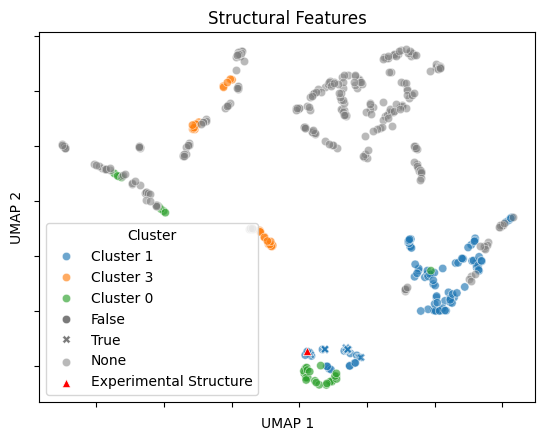

In [86]:
plot_umap_with_experimental_structure(
    structure_features_without_background_umap,
    structure_features_without_background.loc[selected_stucture_features, 'cluster'].to_numpy(),
    structure_features_without_background.loc[selected_stucture_features, 'experimental_structure'].to_numpy(),
    reference=structure_features_without_background.loc[selected_stucture_features, 'has_structure'].to_numpy(),
    title='Structural Features',
)
plt.show()

In [87]:
structure_features_values = structure_features.select_dtypes('number')
structure_features_values = structure_features_values[
    [
        column_name
        for column_name in structure_features_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]

structure_features_values = drop_constant_columns(structure_features_values)
structure_features_values = structure_features_values.dropna()

selected_stucture_features = structure_features_values.index

structure_features_values = structure_features_values.to_numpy()

In [88]:
structure_features_values_norm = StandardScaler().fit_transform(structure_features_values)
structure_features_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(structure_features_values_norm)

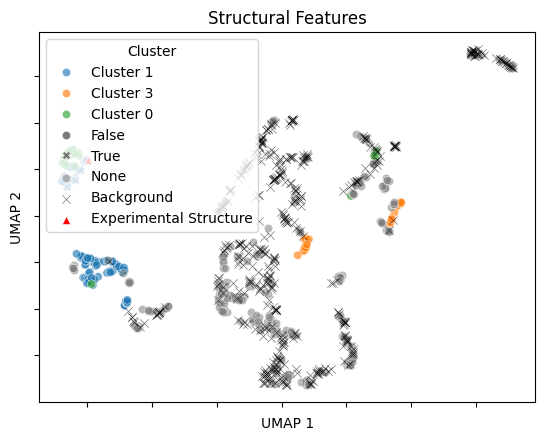

In [89]:
plot_umap_with_experimental_structure(
    structure_features_umap,
    structure_features.loc[selected_stucture_features, 'cluster'].to_numpy(),
    structure_features.loc[selected_stucture_features, 'experimental_structure'].to_numpy(),
    reference=structure_features.loc[selected_stucture_features, 'has_structure'].to_numpy(),
    title='Structural Features',
)

plt.show()

##### Contact Maps

In [90]:
bmlf_contact_maps = pd.read_csv('../data/interim/tcr_pmhc_contacts.csv').merge(
    bmlf_structures, how='inner', left_on='name', right_index=True
)

In [91]:
bmlf_contact_maps['relative_pos_centre_tcr'] = bmlf_contact_maps['relative_pos_centre_tcr'].astype(int)
bmlf_contact_maps['resi_pmhc'] = bmlf_contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

In [92]:
bmlf_contact_maps['chain_type_pmhc'].unique()

array(['mhc_chain1', 'antigen_chain'], dtype=object)

In [93]:
bmlf_contact_maps_antigens = bmlf_contact_maps[bmlf_contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [94]:
bmlf_contact_maps_antigens['relative_pos_centre_pmhc'] = bmlf_contact_maps_antigens['relative_pos_centre_pmhc'].astype(
    int
)

In [95]:
bmlf_contact_map_antigens_scores = (
    bmlf_contact_maps_antigens.groupby('name')
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index='name',
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
bmlf_contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in bmlf_contact_map_antigens_scores.columns.to_flat_index()
]

In [96]:
bmlf_contact_maps_mhc = bmlf_contact_maps[bmlf_contact_maps['chain_type_pmhc'] == 'mhc_chain1'].copy()

In [97]:
bmlf_contact_map_mhc_scores = (
    bmlf_contact_maps_mhc.groupby('name')
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index='name',
        columns=['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

bmlf_contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in bmlf_contact_map_mhc_scores.columns.to_flat_index()
]

In [98]:
bmlf_contact_map_scores = (
    pd.concat([bmlf_contact_map_antigens_scores, bmlf_contact_map_mhc_scores], axis=1).fillna(0).map(int)
)
bmlf_contact_map_column_names = bmlf_contact_map_scores.columns

bmlf_contact_map_scores = bmlf_contact_map_scores.reset_index()

In [99]:
contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_dash_bmlf.csv')

In [100]:
contact_maps['relative_pos_centre_tcr'] = contact_maps['relative_pos_centre_tcr'].astype(int)

In [101]:
contact_maps['resi_pmhc'] = contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

In [102]:
contact_maps['chain_type_pmhc'].unique()

array(['antigen_chain', 'mhc_chain1'], dtype=object)

In [103]:
contact_maps_antigens = contact_maps[contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [104]:
contact_maps_antigens['relative_pos_centre_pmhc'] = contact_maps_antigens['relative_pos_centre_pmhc'].astype(int)

In [105]:
contact_map_antigens_scores = (
    contact_maps_antigens.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_antigens_scores.columns.to_flat_index()
]

In [106]:
contact_maps_mhc = contact_maps[contact_maps['chain_type_pmhc'] == 'mhc_chain1'].copy()

In [107]:
contact_map_mhc_scores = (
    contact_maps_mhc.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_mhc_scores.columns.to_flat_index()
]

In [108]:
contact_map_scores = pd.concat([contact_map_antigens_scores, contact_map_mhc_scores], axis=1).fillna(0).map(int)
contact_map_scores = drop_constant_columns(contact_map_scores)
contact_map_column_names = contact_map_scores.columns

contact_map_scores = contact_map_scores.reset_index()

In [109]:
bmlf_contact_map_scores['experimental_structure'] = True
contact_map_scores['experimental_structure'] = False

contact_map_scores = pd.concat([contact_map_scores, bmlf_contact_map_scores]).reset_index(drop=True)

feature_columns = [
    column
    for column in contact_map_scores.columns
    if column not in ('name', 'seed', 'sample', 'experimental_structure')
]
contact_map_scores[feature_columns] = contact_map_scores[feature_columns].fillna(0).astype(int)

In [110]:
contact_map_scores = contact_map_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
contact_map_scores['cluster'] = contact_map_scores['cluster'].fillna('Background')
contact_map_scores.loc[contact_map_scores['experimental_structure'], 'cluster'] = None

In [111]:
contact_map_scores = contact_map_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)
contact_map_scores_without_background = contact_map_scores.query("cluster != 'Background'")

In [112]:
contact_map_scores_without_background_norm = StandardScaler().fit_transform(
    contact_map_scores_without_background[contact_map_column_names]
)

In [113]:
contact_map_scores_without_background_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    contact_map_scores_without_background_norm
)

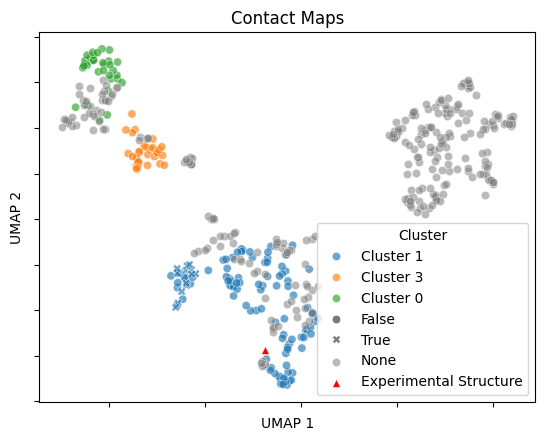

In [114]:
plot_umap_with_experimental_structure(
    contact_map_scores_without_background_umap,
    contact_map_scores_without_background['cluster'].to_numpy(),
    contact_map_scores_without_background['experimental_structure'].to_numpy(),
    reference=contact_map_scores_without_background['has_structure'].to_numpy(),
    title='Contact Maps',
)
plt.show()

In [115]:
contact_map_scores_norm = StandardScaler().fit_transform(contact_map_scores[contact_map_column_names])

In [116]:
contact_map_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(contact_map_scores_norm)

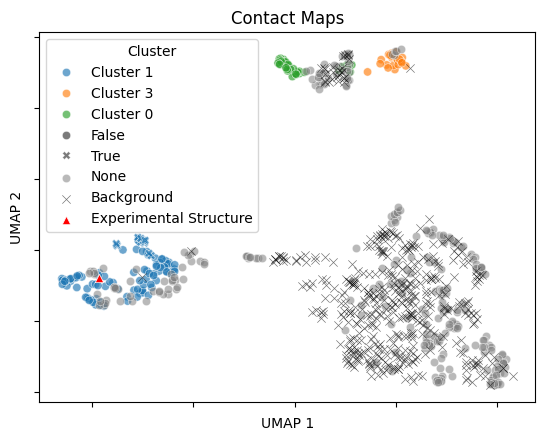

In [117]:
plot_umap_with_experimental_structure(
    contact_map_umap,
    contact_map_scores['cluster'].to_numpy(),
    contact_map_scores['experimental_structure'].to_numpy(),
    reference=contact_map_scores['has_structure'].to_numpy(),
    title='Contact Maps',
)
plt.show()

##### Interactions

In [118]:
bmlf_interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions.csv').merge(
    bmlf_structures, how='inner', left_on='name', right_index=True
)

In [119]:
bmlf_interactions_scores = (
    bmlf_interactions.groupby('name')['type']
    .value_counts()
    .reset_index()
    .pivot_table(index='name', columns='type', values='count')
    .fillna(0)
    .map(int)
    .reset_index()
)

In [120]:
interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_dash_bmlf.csv')

In [121]:
interactions_scores = (
    interactions.groupby(['name', 'seed', 'sample'])['type']
    .value_counts()
    .reset_index()
    .pivot_table(index=['name', 'seed', 'sample'], columns='type', values='count')
    .fillna(0)
    .map(int)
)
interactions_scores_column_names = interactions_scores.columns

interactions_scores = interactions_scores.reset_index()

In [122]:
interactions_scores['experimental_structure'] = False
bmlf_interactions_scores['experimental_structure'] = True

interactions_scores = pd.concat([interactions_scores, bmlf_interactions_scores]).reset_index(drop=True)
interactions_scores[interactions_scores_column_names] = (
    interactions_scores[interactions_scores_column_names].fillna(0).map(int)
)

In [123]:
interactions_scores = interactions_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
interactions_scores['cluster'] = interactions_scores['cluster'].fillna('Background')

interactions_scores.loc[interactions_scores['experimental_structure'], 'cluster'] = None

interactions_scores[interactions_scores_column_names] = interactions_scores[interactions_scores_column_names].fillna(0)

In [124]:
interactions_scores = interactions_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)
interactions_scores_without_background = interactions_scores.query("cluster != 'Background'")

In [125]:
interactions_scores_without_background_norm = StandardScaler().fit_transform(
    interactions_scores_without_background[interactions_scores_column_names]
)

In [126]:
interactions_scores_without_background_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    interactions_scores_without_background_norm
)

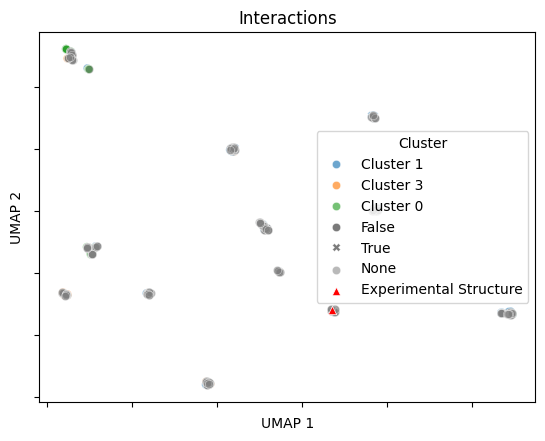

In [127]:
plot_umap_with_experimental_structure(
    interactions_scores_without_background_umap,
    interactions_scores_without_background['cluster'].to_numpy(),
    interactions_scores_without_background['experimental_structure'].to_numpy(),
    reference=interactions_scores_without_background['has_structure'].to_numpy(),
    title='Interactions',
)
plt.show()

In [128]:
interactions_scores_norm = StandardScaler().fit_transform(interactions_scores[interactions_scores_column_names])

In [129]:
interactions_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(interactions_scores_norm)

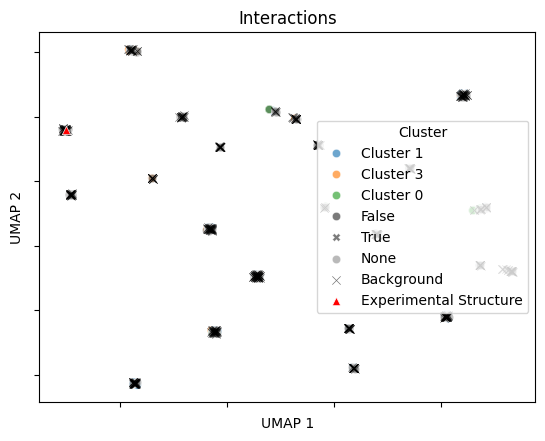

In [130]:
plot_umap_with_experimental_structure(
    interactions_umap,
    interactions_scores['cluster'].to_numpy(),
    interactions_scores['experimental_structure'].to_numpy(),
    reference=interactions_scores['has_structure'].to_numpy(),
    title='Interactions',
)

plt.show()

##### Shape complementarity and buried surface area

In [131]:
bmlf_sc_and_bsa = pd.read_csv('../data/processed/tcr_pmhc_sc_and_bsa.csv').merge(
    bmlf_structures, how='inner', left_on='name', right_index=True
)

In [132]:
sc_and_bsa = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_sc_and_bsa_dash_bmlf.csv')

In [133]:
bmlf_sc_and_bsa['experimental_structure'] = True
sc_and_bsa['experimental_structure'] = False

sc_and_bsa = pd.concat([sc_and_bsa, bmlf_sc_and_bsa]).reset_index(drop=True)

In [134]:
sc_and_bsa = sc_and_bsa.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
sc_and_bsa['cluster'] = sc_and_bsa['cluster'].fillna('Background')

sc_and_bsa.loc[sc_and_bsa['experimental_structure'], 'cluster'] = None

In [135]:
sc_and_bsa = sc_and_bsa.merge(sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id')
sc_and_bsa_without_background = sc_and_bsa.query("cluster != 'Background'")

In [136]:
sc_without_background = sc_and_bsa_without_background[[col for col in sc_and_bsa if col != 'bsa']]
bsa_without_background = sc_and_bsa_without_background[[col for col in sc_and_bsa if col != 'sc']]

In [137]:
sc_without_background_norm = (
    (sc_without_background['sc'] - sc_without_background['sc'].mean()) / sc_without_background['sc'].std()
).to_numpy()
bsa_without_background_norm = (
    (bsa_without_background['bsa'] - bsa_without_background['bsa'].mean()) / bsa_without_background['bsa'].std()
).to_numpy()

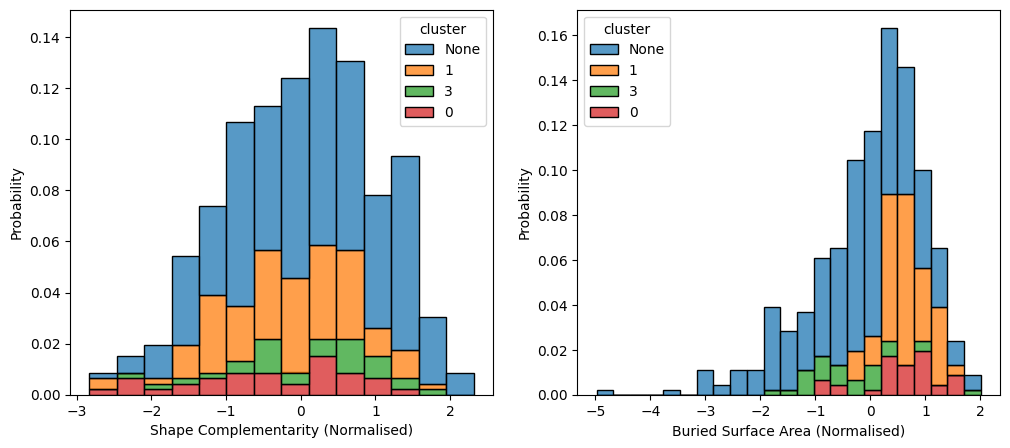

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    x=sc_without_background_norm, hue=sc_without_background['cluster'], multiple='stack', stat='probability', ax=axes[0]
)
axes[0].set_xlabel('Shape Complementarity (Normalised)')

sns.histplot(
    x=bsa_without_background_norm,
    hue=bsa_without_background['cluster'],
    multiple='stack',
    stat='probability',
    ax=axes[1],
)
axes[1].set_xlabel('Buried Surface Area (Normalised)')

plt.show()

In [139]:
sc = sc_and_bsa[[col for col in sc_and_bsa if col != 'bsa']]
bsa = sc_and_bsa[[col for col in sc_and_bsa if col != 'sc']]

In [140]:
sc_norm = ((sc['sc'] - sc['sc'].mean()) / sc['sc'].std()).to_numpy()
bsa_norm = ((bsa['bsa'] - bsa['bsa'].mean()) / bsa['bsa'].std()).to_numpy()

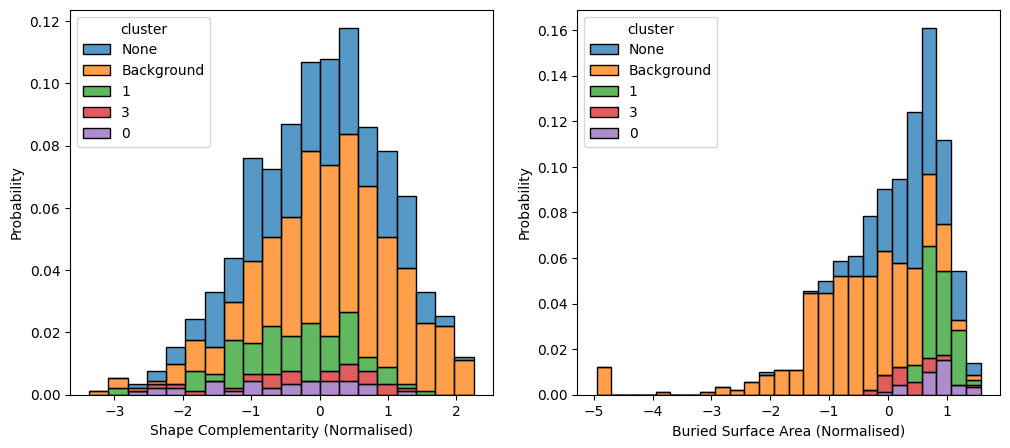

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(x=sc_norm, hue=sc['cluster'], multiple='stack', stat='probability', ax=axes[0])
axes[0].set_xlabel('Shape Complementarity (Normalised)')

sns.histplot(x=bsa_norm, hue=bsa['cluster'], multiple='stack', stat='probability', ax=axes[1])
axes[1].set_xlabel('Buried Surface Area (Normalised)')

plt.show()

##### Combined

In [142]:
combined_scores = (
    structure_features.merge(contact_map_scores, how='inner')
    .merge(interactions_scores, how='inner')
    .merge(sc_and_bsa, how='inner')
)
combined_scores_without_background = combined_scores.query("cluster != 'Background'")

In [143]:
combined_scores_without_background_values = combined_scores_without_background.select_dtypes('number')
combined_scores_without_background_values = combined_scores_without_background_values[
    [
        column_name
        for column_name in combined_scores_without_background_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]
combined_scores_without_background_values = combined_scores_without_background_values.fillna(0.0)
combined_scores_without_background_values = combined_scores_without_background_values.to_numpy()

In [144]:
combined_scores_without_background_values_norm = StandardScaler().fit_transform(
    combined_scores_without_background_values
)

In [145]:
combined_without_background_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(
    combined_scores_without_background_values_norm
)

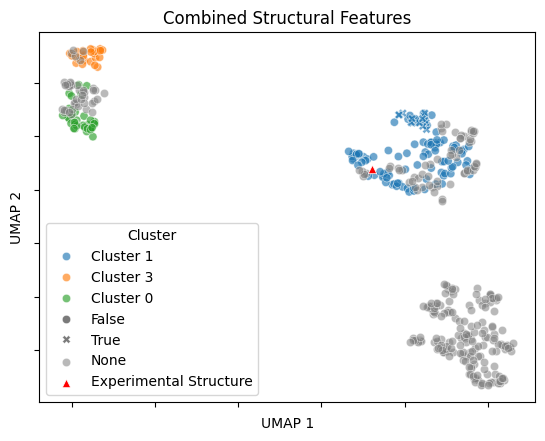

In [146]:
plot_umap_with_experimental_structure(
    combined_without_background_umap,
    combined_scores_without_background['cluster'].to_numpy(),
    combined_scores_without_background['experimental_structure'].to_numpy(),
    reference=combined_scores_without_background['has_structure'].to_numpy(),
    title='Combined Structural Features',
)

plt.savefig('../report/figures/dash_bmlf_combined_structural_features_umap_sequence_labels.svg')
plt.show()

In [147]:
combined_scores_values = combined_scores.select_dtypes('number')
combined_scores_values = combined_scores_values[
    [
        column_name
        for column_name in combined_scores_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]
combined_scores_values = combined_scores_values.fillna(0.0)
combined_scores_values = combined_scores_values.to_numpy()

In [148]:
combined_scores_values_norm = StandardScaler().fit_transform(combined_scores_values)

In [149]:
combined_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(combined_scores_values_norm)

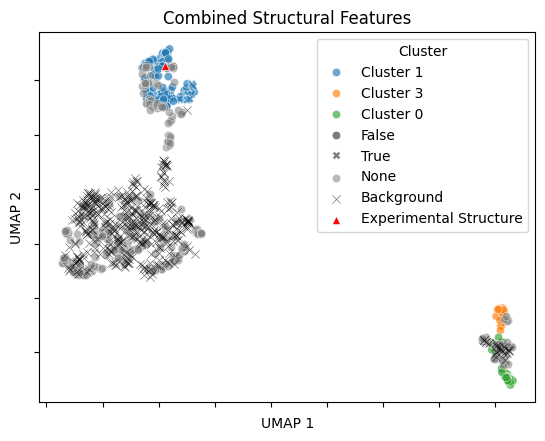

In [150]:
plot_umap_with_experimental_structure(
    combined_umap,
    combined_scores['cluster'].to_numpy(),
    combined_scores['experimental_structure'].to_numpy(),
    reference=combined_scores['has_structure'].to_numpy(),
    title='Combined Structural Features',
)

plt.savefig('../report/figures/dash_bmlf_combined_structural_features_umap_sequence_labels_negatives.svg')
plt.show()

Reversing the structural clusters to the sequence space

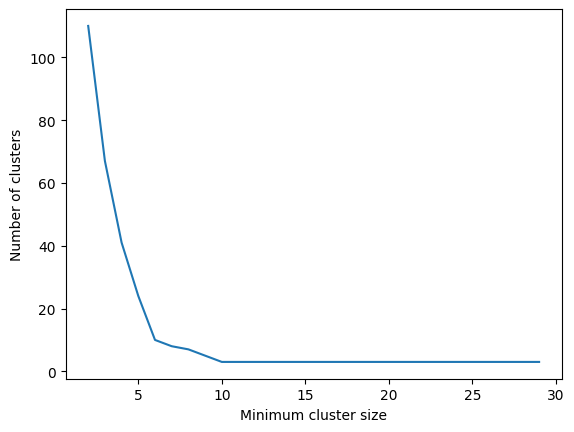

In [151]:
min_cluster_sizes = list(range(2, 30))
num_clusters = []
for min_cluster_size in min_cluster_sizes:
    structural_clusters = HDBSCAN(min_cluster_size=min_cluster_size).fit_predict(
        combined_scores_values_norm[combined_scores['label'].fillna(0).astype(bool)]
    )
    num_clusters.append(len(np.unique(structural_clusters[structural_clusters != -1])))

plt.plot(min_cluster_sizes, num_clusters)

plt.xlabel('Minimum cluster size')
plt.ylabel('Number of clusters')

plt.savefig('../report/figures/dash_bmlf_combined_structural_features_elbow.svg')
plt.show()

In [152]:
structural_clusters = (
    HDBSCAN(min_cluster_size=8)
    .fit_predict(combined_scores_values_norm[combined_scores['label'].fillna(0).astype(bool)])
    .astype(str)
)
structural_clusters[structural_clusters == '-1'] = 'None'

combined_scores['structural_cluster'] = 'Background'
combined_scores.loc[combined_scores['experimental_structure'], 'structural_cluster'] = None
combined_scores.loc[combined_scores['label'].fillna(0).astype(bool), 'structural_cluster'] = structural_clusters

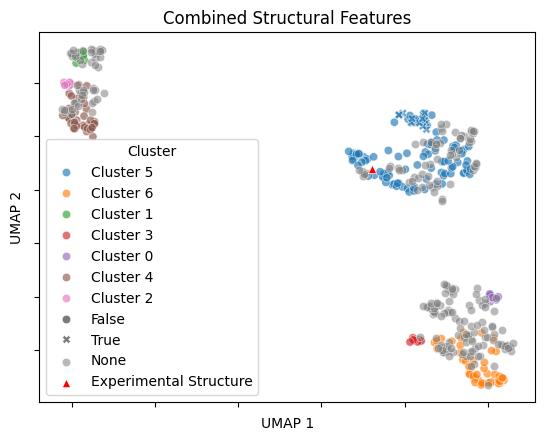

In [153]:
plot_umap_with_experimental_structure(
    combined_without_background_umap,
    combined_scores.query("cluster != 'Background'")['structural_cluster'].to_numpy(),
    combined_scores.query("cluster != 'Background'")['experimental_structure'].to_numpy(),
    reference=combined_scores.query("cluster != 'Background'")['has_structure'].to_numpy(),
    title='Combined Structural Features',
)

plt.savefig('../report/figures/dash_bmlf_combined_structural_features_umap.svg')
plt.show()

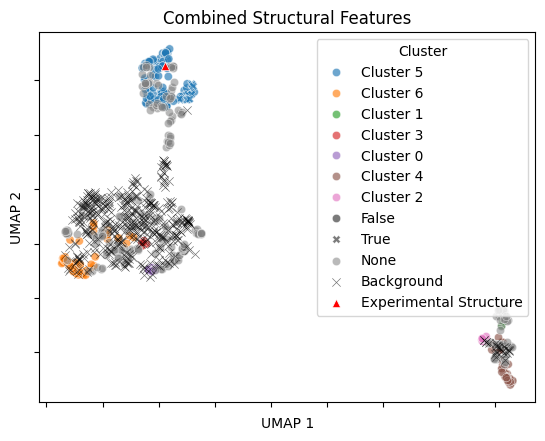

In [154]:
plot_umap_with_experimental_structure(
    combined_umap,
    combined_scores['structural_cluster'].to_numpy(),
    combined_scores['experimental_structure'].to_numpy(),
    reference=combined_scores['has_structure'].to_numpy(),
    title='Combined Structural Features',
)

plt.savefig('../report/figures/dash_bmlf_combined_structural_features_umap_with_negatives.svg')
plt.show()

In [155]:
agg_structural_clusters = (
    combined_scores[combined_scores['label'].fillna(0).astype(bool)].groupby('name')['structural_cluster'].apply(list)
)

In [156]:
def count_clusters(clusters: list) -> dict[str, int]:
    count = {}
    for cluster in clusters:
        if cluster not in count:
            count[cluster] = 1

        else:
            count[cluster] += 1

    return count


agg_structural_clusters = agg_structural_clusters.apply(count_clusters)

In [157]:
def get_consensus(cluster_counts: dict) -> str:
    """Get the consensus clustuer from the counts.

    Note: does not handle ties.

    """
    max_count = 0
    consensus_cluster = None

    for cluster, count in cluster_counts.items():
        if count > max_count:
            consensus_cluster = cluster
            max_count = count

    return consensus_cluster


agg_structural_clusters = agg_structural_clusters.apply(get_consensus)

In [158]:
dash_bmlf = dash_bmlf.merge(agg_structural_clusters.to_frame(), how='left', left_on='id', right_index=True)

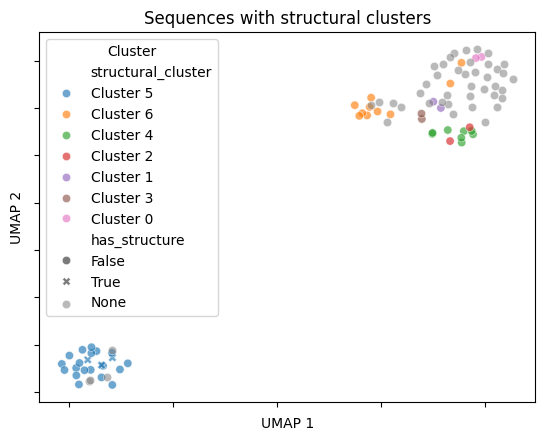

In [159]:
plot_umap(
    sequence_umap,
    dash_bmlf['structural_cluster'],
    reference=dash_bmlf['has_structure'],
    title='Sequences with structural clusters',
)

plt.savefig('../report/figures/dash_bmlf_sequence_umap_structure_labels.svg')
plt.show()

""


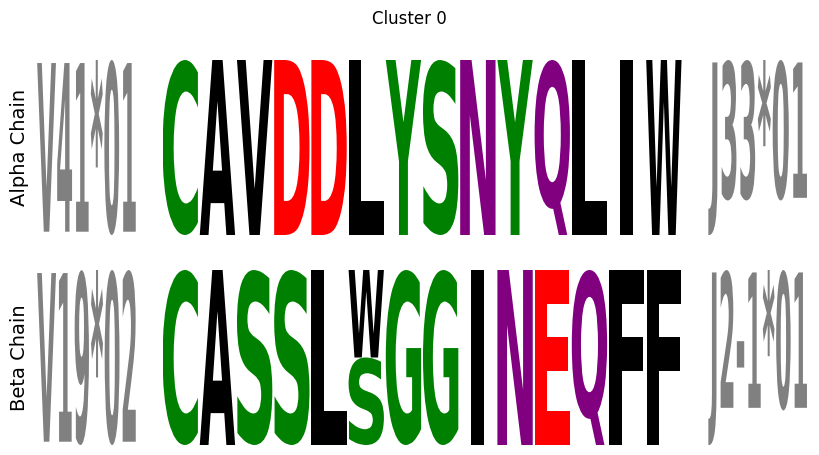

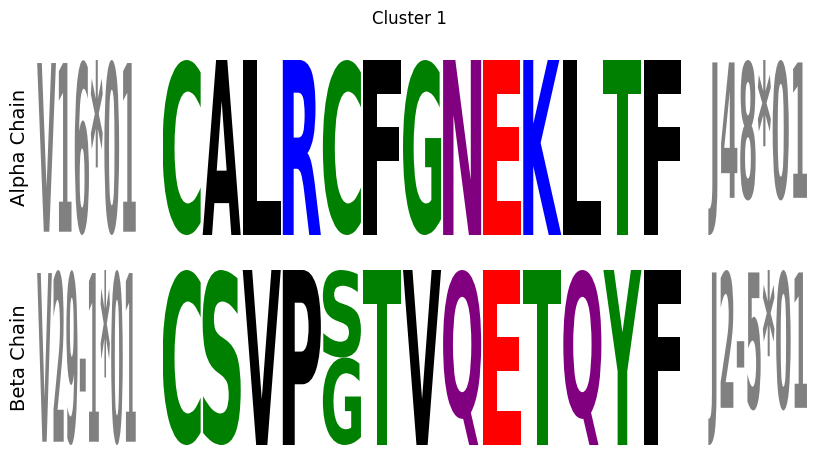

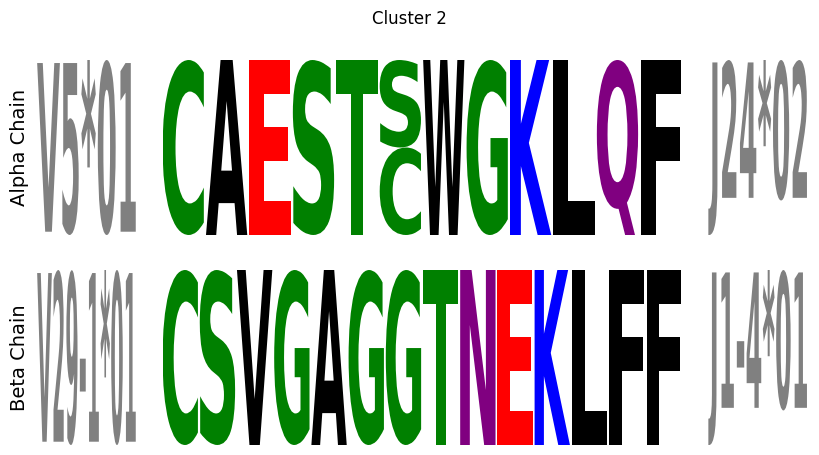

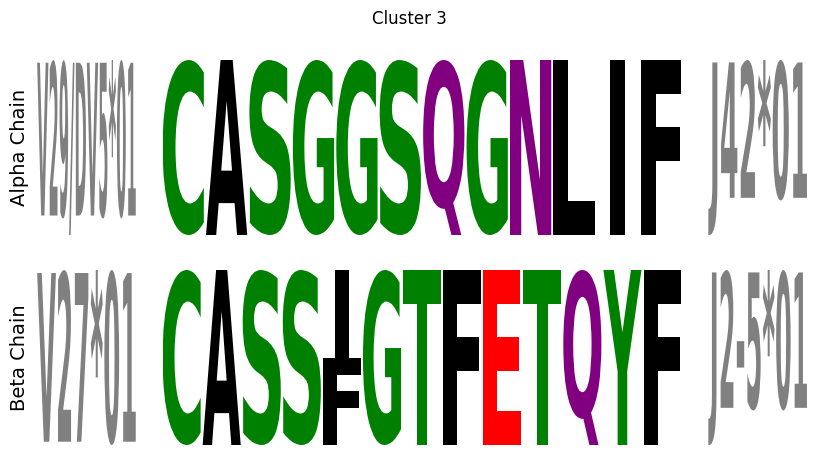

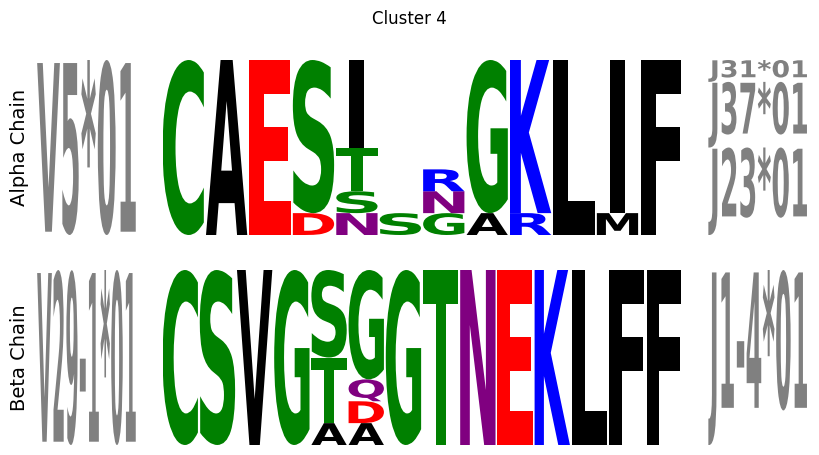

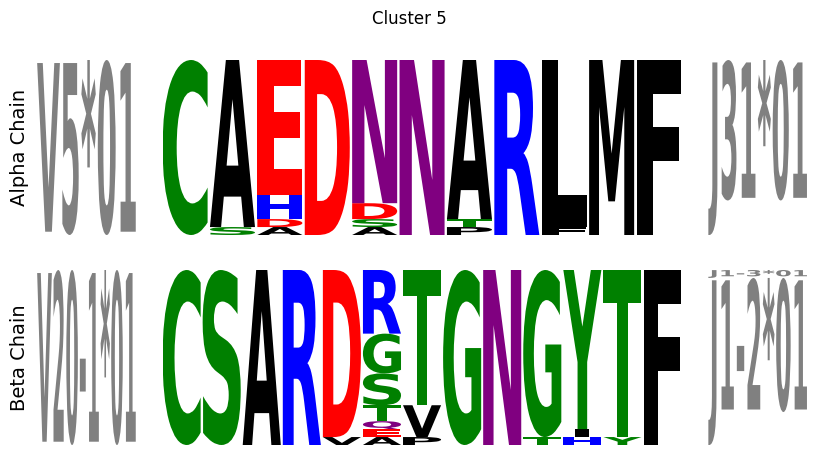

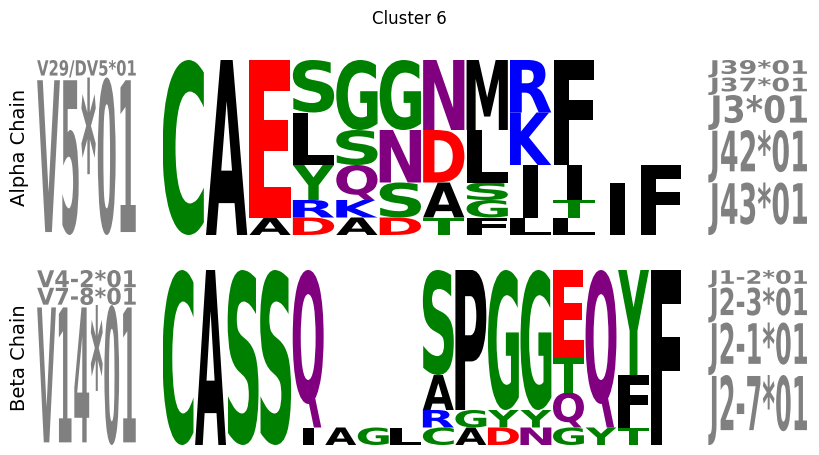

In [160]:
dash_bmlf.query("structural_cluster != 'None'").groupby('structural_cluster').apply(
    make_logo_plot,
    save=True,
    save_name='../report/figures/dash_bmlf_motif_structure_cluster_{cluster_name}.svg',
    include_groups=False,
)

In [161]:
num_sequences = len(dash_bmlf)

num_seq_clustered = len(dash_bmlf.query("cluster != 'None'"))
seq_cluster = (num_seq_clustered / num_sequences) * 100
print(f'Percent clustered by sequences: {seq_cluster:.2f}% ({num_seq_clustered} of {num_sequences})')

num_struct_clustered = len(dash_bmlf.query("structural_cluster != 'None'"))
struct_cluster = (num_struct_clustered / num_sequences) * 100
print(f'Percent clustered by structures: {struct_cluster:.2f}% ({num_struct_clustered} of {num_sequences})')

num_struct_no_seq = len(dash_bmlf.query("cluster == 'None' and structural_cluster != 'None'"))
num_no_seq = len(dash_bmlf.query("cluster == 'None'"))
struct_cluster_no_seq = (num_struct_no_seq / num_no_seq) * 100
print(
    f'Percent clustered by structures not clustered by sequences: {struct_cluster_no_seq:.2f}% ({num_struct_no_seq} of '
    f'{num_no_seq})'
)

num_seq_no_struct = len(dash_bmlf.query("cluster != 'None' and structural_cluster == 'None'"))
seq_cluster_no_struct = (num_seq_no_struct / num_seq_clustered) * 100
print(
    f'Percent clustered by sequences not clustered by structures: {seq_cluster_no_struct:.2f}% ({num_seq_no_struct} of '
    f'{num_seq_clustered})'
)

num_no_cluster = len(dash_bmlf.query("cluster == 'None' and structural_cluster == 'None'"))
no_cluster = (num_no_cluster / num_sequences) * 100
print(f'Percent not clustered: {no_cluster:.2f}% ({num_no_cluster} of {num_sequences})')

print()

print(f"Adjusted Rand Index: {adjusted_rand_score(dash_bmlf['cluster'], dash_bmlf['structural_cluster']):.2f}")
print(f"V-measure: {v_measure_score(dash_bmlf['cluster'], dash_bmlf['structural_cluster']):.2f}")

Percent clustered by sequences: 38.04% (35 of 92)
Percent clustered by structures: 52.17% (48 of 92)
Percent clustered by structures not clustered by sequences: 31.58% (18 of 57)
Percent clustered by sequences not clustered by structures: 14.29% (5 of 35)
Percent not clustered: 42.39% (39 of 92)

Adjusted Rand Index: 0.47
V-measure: 0.59


## pp65 Epitope Analysis

In [162]:
dash_pp65 = dash.query("epitope == 'pp65'").copy()

In [163]:
distance_matrix = calculate_sequence_distances(dash_pp65['cdr3_a_aa'].tolist(), dash_pp65['cdr3_b_aa'].tolist())
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [164]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [165]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [166]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [167]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [168]:
unique_subjects = sorted(dash_pp65['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_pp65['subject'].to_numpy()[new_order]])

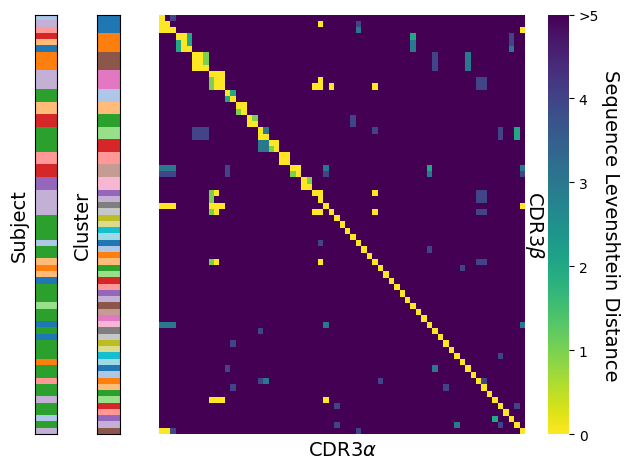

In [169]:
plot_sequence_distances(distance_matrix, cluster_colours, cluster_order, cluster_counts, new_order, subject_colours)

plt.savefig('../report/figures/dash_pp65_sequence_distance.svg')
plt.show()

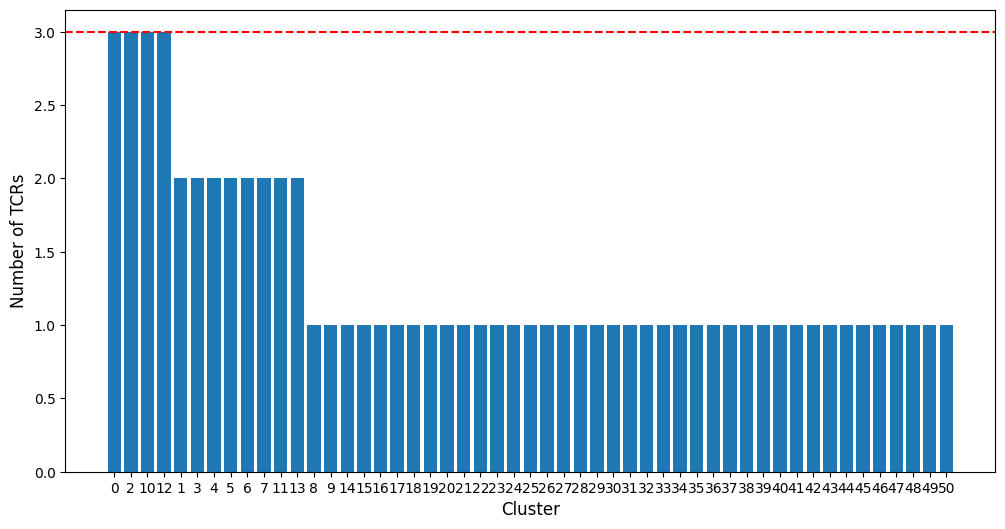

In [170]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(MIN_CLUSTER_SIZE - 1, color='red', linestyle='--')

plt.show()

In [171]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [172]:
dash_pp65['cluster'] = clusters_filtered
dash_pp65['cluster'] = dash_pp65['cluster'].astype(str)
dash_pp65['cluster'] = dash_pp65['cluster'].replace('-1', 'None')

In [173]:
dash_pp65.query("cluster != 'None'").groupby('cluster').apply(make_logo_plot, include_groups=False)

,id,subject,epitope,count,v_a_gene,j_a_gene,cdr3_a_aa,v_b_gene,j_b_gene,cdr3_b_aa,clone_id
cluster,,,,,,,,,,,


In [174]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

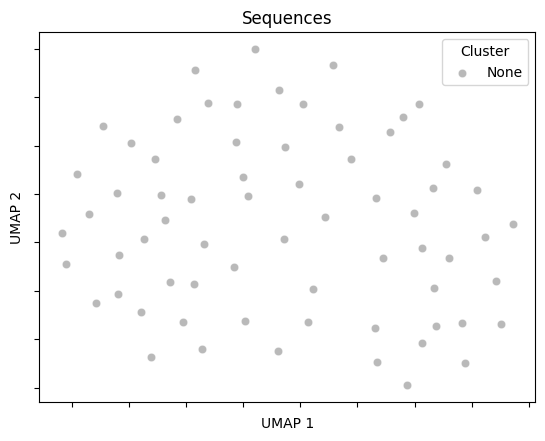

In [175]:
plot_umap(sequence_umap, dash_pp65['cluster'], title='Sequences')

plt.savefig('../report/figures/dash_pp65_sequence_umap.svg')
plt.show()

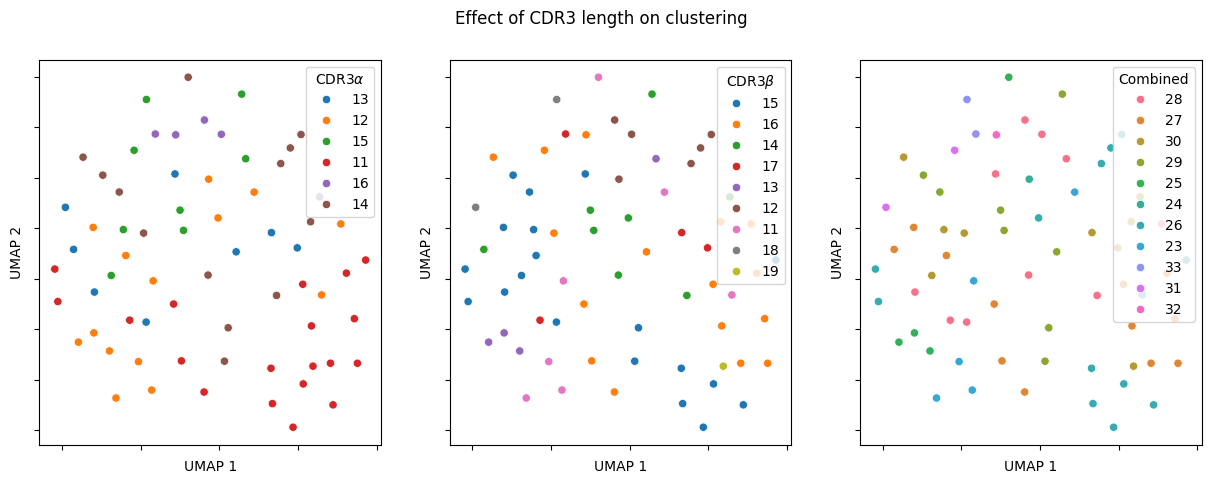

In [176]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

fig.suptitle('Effect of CDR3 length on clustering')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_pp65['cdr3_a_aa'].str.len().astype(str), ax=axes[0]
)
axes[0].legend(title=r'CDR3$\alpha$')

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])

axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0], y=sequence_umap[:, 1], hue=dash_pp65['cdr3_b_aa'].str.len().astype(str), ax=axes[1]
)
axes[1].legend(title=r'CDR3$\beta$')

axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')

sns.scatterplot(
    x=sequence_umap[:, 0],
    y=sequence_umap[:, 1],
    hue=(dash_pp65['cdr3_a_aa'].str.len() + dash_pp65['cdr3_b_aa'].str.len()).astype(str),
    ax=axes[2],
)
axes[2].legend(title=r'Combined')

axes[2].set_yticklabels([])
axes[2].set_xticklabels([])

axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')

plt.show()

In [177]:
sequences_with_negatives_pp65 = sequences_with_negatives.query("name == 'pp65'")

In [178]:
sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65 = sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65['cluster'] = sequences_with_negatives_pp65['cluster'].fillna('Background')

In [179]:
distance_matrix = calculate_sequence_distances(
    sequences_with_negatives_pp65['cdr3_alpha'].tolist(), sequences_with_negatives_pp65['cdr3_beta'].tolist()
)
cdr3_distance_matrix = distance_matrix + distance_matrix.T

In [180]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

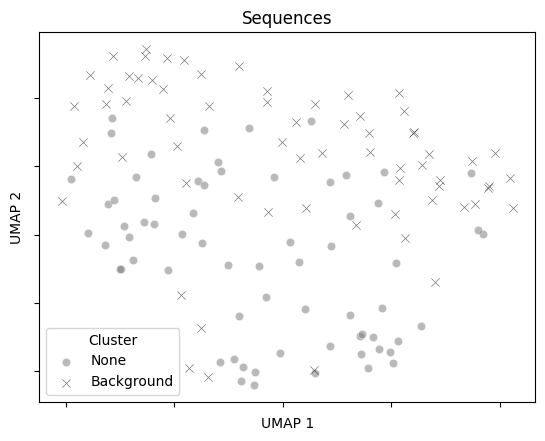

In [181]:
plot_umap(sequence_umap, sequences_with_negatives_pp65['cluster'], title='Sequences')

plt.savefig('../report/figures/dash_pp65_sequence_umap_with_negatives.svg')
plt.show()